# Check the gridcells of the corner LAI-aridity bins

**Env:** `etunc` kernel (pixi env).

The land area and sample count heatmaps of the LAI-aridity bins (`bin_area.py`, `bin_all_clim.py`)
are dense in two corners:
- **upper left**: high LAI, low aridity (wet, densely vegetated);
- **lower right**: low LAI, high aridity (dry, sparsely vegetated).

This notebook finds the gridcells that land in those corner bins, maps where they are, and plots
histograms of their ET, for every family of a run (sections 1-6). Corner bins are open-ended: the clip
in `binning._bin_stats_flat` puts every value beyond the outermost edges into them, so they can hold
the long tails of the LAI and AI distributions (e.g. AI up to ~140 in deserts).

Some members have dense bins near a corner but not in the exact corner bin. Section 7 selects, per
member, the bins near each corner with a land fraction far above that of a uniform bin, and repeats
the same diagnosis for their gridcells.

Each gridcell's bin is computed here exactly as in `bin_stats` (`searchsorted(side="right")`, then
clipped into the edge bins), on the common area mask, with the climatological LAI and AI of
the member. Sections 2 and 7 check this against the saved outputs of the run.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import regionmask
from IPython.display import display

import etunc.config as cfg
import etunc.binning as binning
import etunc.edges as edges
import etunc.grid as rg
import etunc.plotting as plotting
import etunc.temporal as temporal

## Settings

In [20]:
RUN_ID = "r183a58a"  # run whose edges, common area and bins are checked (r183a58a: defaults, 15 x 15 bins, unweighted)
EDGES = "pooled_all"  # "pooled_all" (edges of every family pooled) or "pooled_family" (each family's own edges)
ET_SAMPLES = "clim"   # "clim": one climatological ET per gridcell (bin_all_clim.py); "annual": every gridcell-year (bin_all.py)
N_CORNER = 1          # corner block size in bins: 1 = the corner bin only, 2 = the 2 x 2 bins of the corner, ...

# Each corner by its end of the LAI (y) and AI (x) axes
CORNERS = {
    "upper_left": {"lai": "high", "ai": "low"},   # high LAI, low aridity
    "lower_right": {"lai": "low", "ai": "high"},  # low LAI, high aridity
    # "lower_left": {"lai": "low", "ai": "low"},  # also dense in several CMIP6 models (high latitudes, AI < 0.5)
}

# Dense bins near the corners (section 7)
DENSE_FACTOR = 4     # a bin is dense if it holds more than DENSE_FACTOR / (n_ybins * n_xbins) of the member's land
REGION_FRAC = 7 / 15 # 1 / 3  # region of each corner: this fraction of the bins of each axis at the corner's ends

DETAIL_FAMILY = "cmip"  # family with per-member maps and histograms (sections 6 and 7)

# Settings registered under RUN_ID in config/runs.csv, not those of the current config
SETTINGS = cfg.run_settings(RUN_ID)
PREP_ID = cfg.settings_id(SETTINGS, ("prep",), "p")
FAMILIES = SETTINGS["binning"]["families"]
AREA_WEIGHTED = SETTINGS["binning"]["area_weighted"]
N_YBINS = SETTINGS["binning"]["n_ybins"]
N_XBINS = SETTINGS["binning"]["n_xbins"]
TARGET_RES = SETTINGS["prep"]["target_res"]
LAT_BNDS = slice(*SETTINGS["prep"]["lat_bnds"])
print(f"run {RUN_ID}, prep {PREP_ID}: {FAMILIES}, {N_YBINS} x {N_XBINS} bins, "
      f"area weighted: {AREA_WEIGHTED}, ET samples: {ET_SAMPLES}")

run r183a58a, prep p2abea0a: ['obs', 'era5', 'cmip', 'fppe', 'ippe', 'lens', 'trendy_s3'], 15 x 15 bins, area weighted: False, ET samples: clim


## 1. Load the inputs and find the corner gridcells

In [3]:
def edges_kind(family: str) -> str:
    """Edge set of a family: the pooled_all edges, or its own."""
    return EDGES if EDGES == "pooled_all" else f"pooled_{family}"


def bin_index(da: xr.DataArray, bin_edges: np.ndarray) -> xr.DataArray:
    """
    Bin of every value, as in `binning._bin_stats_flat`: bins are [lower, upper), the maximum and
    out-of-range values are clipped into the first/last bin; -1 where the value is NaN.
    """
    e = np.asarray(bin_edges, dtype=float)
    idx = np.clip(np.searchsorted(e, da.values, side="right") - 1, 0, len(e) - 2)
    return da.copy(data=np.where(np.isfinite(da.values), idx, -1)).astype(int)


def corner_bins(bin_edges: np.ndarray, end: str, n: int = N_CORNER) -> np.ndarray:
    """
    Indices of the `n` bins at the `end` ("low" or "high") of an axis, skipping zero-width bins
    (duplicate quantile edges), which are always empty.
    """
    nonzero = np.flatnonzero(np.diff(bin_edges) > 0)
    return nonzero[:n] if end == "low" else nonzero[-n:]


# Common area mask of the run (make_edges.py) and the land area of each gridcell
area = xr.open_dataset(cfg.area_mask_path(RUN_ID))["area_mask"] == 1
land = rg.land_area(rg.target_grid(TARGET_RES)).sel(lat=area.lat, lon=area.lon)
rg.check_same_grid(land, area, "land area")
land_common = float(land.where(area).sum())
print(f"common area: {int(area.sum())} gridcells, {land_common:.4g} km2")

data = {}       # family -> Dataset of the member fields: et, lai, ai, y_bin, x_bin, in_<group>
bin_edges = {}  # family -> (LAI edges, AI edges)
bounds = {}     # family -> {corner: {"lai": (lower, upper), "ai": (lower, upper), "y_bins", "x_bins"}}
for family in FAMILIES:
    kind = edges_kind(family)
    y_edges = edges.load_bin_edges(kind, "lai", RUN_ID).values
    x_edges = edges.load_bin_edges(kind, "ai", RUN_ID).values
    bin_edges[family] = (y_edges, x_edges)

    with xr.open_dataset(cfg.inputs_path(family, PREP_ID)) as f:
        inputs = f[["et", "lai", "ai"]].load()
    # ET samples of bin_all_clim.py (mean over the years, NaN years skipped) or bin_all.py (annual)
    et = temporal.aggregate(inputs["et"], "clim", label=f"{family} et") if ET_SAMPLES == "clim" else inputs["et"]

    ds = xr.Dataset({"et": et, "lai": inputs["lai"], "ai": inputs["ai"]})
    ds["y_bin"] = bin_index(inputs["lai"], y_edges).transpose("member", "lat", "lon")
    ds["x_bin"] = bin_index(inputs["ai"], x_edges).transpose("member", "lat", "lon")

    bounds[family] = {}
    for corner, ends in CORNERS.items():
        yb = corner_bins(y_edges, ends["lai"])
        xb = corner_bins(x_edges, ends["ai"])
        # A gridcell of the common area whose climatological LAI and AI both fall in the corner bins
        ds[f"in_{corner}"] = (ds["y_bin"].isin(yb) & ds["x_bin"].isin(xb) & area).transpose("member", "lat", "lon")
        bounds[family][corner] = {
            "lai": (y_edges[yb.min()], y_edges[yb.max() + 1]), "ai": (x_edges[xb.min()], x_edges[xb.max() + 1]),
            "y_bins": yb, "x_bins": xb,
        }
    data[family] = ds
    del inputs

# Bounds of the corner bins (open-ended: values beyond the outermost edges are clipped into them)
display(pd.DataFrame(
    {(f, c): {"lai": "[{:.3g}, {:.3g}]".format(*b["lai"]), "ai": "[{:.3g}, {:.3g}]".format(*b["ai"]),
              "y_bins": list(b["y_bins"]), "x_bins": list(b["x_bins"])}
     for f, fb in bounds.items() for c, b in fb.items()}
).T)

common area: 10087 gridcells, 9.083e+07 km2
obs et: climatology of 14 years; 68013 gridcells have missing years (fewest valid years: 1)
era5 et: climatology of 14 years; 2 gridcells have missing years (fewest valid years: 13)
cmip et: climatology of 14 years; 215 gridcells have missing years (fewest valid years: 1)
fppe et: climatology of 14 years; 8 gridcells have missing years (fewest valid years: 13)
ippe et: climatology of 14 years; 108 gridcells have missing years (fewest valid years: 12)
lens et: climatology of 14 years; 34 gridcells have missing years (fewest valid years: 12)
trendy_s3 et: climatology of 14 years; 217 gridcells have missing years (fewest valid years: 1)


lai               ai y_bins x_bins
obs       upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
era5      upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
cmip      upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
fppe      upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
ippe      upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
lens      upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]
trendy_s3 upper_left       [4.66, 13.4]  [-0.279, 0.536]   [14]    [0]
          lower_right  [-0.0017, 0.159]      [3.58, 141]    [0]   [14]

## 2. Check the bin assignment against the saved bin statistics

The count and mean ET of each member's corner bins, recomputed from the gridcells above, should
equal those of the run's `bin_all_clim.py` (or `bin_all.py`) output. Only checked for
`N_CORNER = 1` (one bin per corner).

In [4]:
def saved_bin_stats(family: str) -> xr.DataArray:
    """Per-member bin statistics of the run, (member, stats, y_bin, x_bin)."""
    var = "et_clim" if ET_SAMPLES == "clim" else "et"
    kind = edges_kind(family)
    path = cfg.output_dir(cfg.PROC_ROOT, family, "qbin", RUN_ID) / f"{family}.{var}.qbin_{kind}.{RUN_ID}.nc"
    return xr.open_dataarray(path)


def member_dims(da: xr.DataArray) -> list[str]:
    """Every dimension of `da` but member (lat, lon and, for annual ET, year)."""
    return [d for d in da.dims if d != "member"]


if N_CORNER == 1:
    rows = []
    for family, ds in data.items():
        bs = saved_bin_stats(family)
        for corner in CORNERS:
            b = bounds[family][corner]
            saved = bs.isel(y_bin=int(b["y_bins"][0]), x_bin=int(b["x_bins"][0]))
            # Samples of the corner: the ET of its gridcells (and years), weighted by land area if the run is
            valid = ds["et"].where(ds[f"in_{corner}"]).notnull()
            w = (land if AREA_WEIGHTED else xr.ones_like(land)).where(valid)
            count = valid.sum(member_dims(valid))
            mean = (ds["et"] * w).sum(member_dims(w)) / w.sum(member_dims(w))
            rows.append({
                "family": family, "corner": corner,
                "count_equal": bool((count.values == saved.sel(stats="count").values).all()),
                "max_abs_mean_diff": float(np.nanmax(np.abs(mean.values - saved.sel(stats="mean").values))),
            })
    check = pd.DataFrame(rows)
    display(check)
    assert check["count_equal"].all() and (check["max_abs_mean_diff"] < 1e-8).all(), "bin assignment differs from the run"

,family,corner,count_equal,max_abs_mean_diff
0,obs,upper_left,True,5.684342e-14
1,obs,lower_right,True,1.065814e-14
2,era5,upper_left,True,0.000000e+00
3,era5,lower_right,True,0.000000e+00
4,cmip,upper_left,True,5.684342e-14
5,cmip,lower_right,True,2.842171e-14
6,fppe,upper_left,True,7.105427e-14
7,fppe,lower_right,True,1.776357e-14
8,ippe,upper_left,True,9.947598e-14
9,ippe,lower_right,True,1.421085e-14


## Diagnostics of a group of gridcells

A group is a set of gridcells of each member, the boolean `in_<group>` (member, lat, lon) of each
family's dataset: `upper_left` / `lower_right` are the exact corner bins (sections 3-6), and
`dense_upper_left` / `dense_lower_right` the dense bins near each corner (section 7). Every function
below takes a group name, so both are diagnosed the same way.

In [5]:
def corner_of(group: str) -> str:
    """Corner of a group: "upper_left" for both "upper_left" and "dense_upper_left"."""
    return group.removeprefix("dense_")


def summary_table(groups) -> pd.DataFrame:
    """
    Per member: number of bins holding the group's gridcells, number of gridcells and % of the common
    land area; median, min and max across the members of each family.
    """
    rows = []
    for group in groups:
        for family, ds in data.items():
            mask = ds[f"in_{group}"]
            n_cells = mask.sum(("lat", "lon"))
            pct_land = 100 * land.where(mask).sum(("lat", "lon")) / land_common
            # Distinct (y_bin, x_bin) of the group's gridcells, per member
            lin = (ds["y_bin"] * N_XBINS + ds["x_bin"]).where(mask).values
            n_bins = np.array([np.unique(v[np.isfinite(v)]).size for v in lin])
            rows.append({
                "group": group, "family": family, "members": ds.sizes["member"],
                "members_none": int((n_cells == 0).sum()),
                "bins_median": float(np.median(n_bins)), "bins_max": int(n_bins.max()),
                "cells_median": float(n_cells.median()), "cells_min": int(n_cells.min()), "cells_max": int(n_cells.max()),
                "pct_land_median": float(pct_land.median()), "pct_land_min": float(pct_land.min()),
                "pct_land_max": float(pct_land.max()),
            })
    return pd.DataFrame(rows).set_index(["group", "family"]).round(2)


def plot_lai_ai_hist(group: str):
    """
    LAI and AI of the group's gridcells, one line per family, all members pooled (each weighing equally).
    Log AI bins for the high-AI corner, whose AI spans two orders of magnitude in hyperarid deserts.
    """
    corner = corner_of(group)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for ax, var in zip(axs, ("lai", "ai")):
        vals = {f: ds[var].values[ds[f"in_{group}"].values] for f, ds in data.items()}
        allv = np.concatenate([v for v in vals.values() if v.size])
        log = var == "ai" and CORNERS[corner]["ai"] == "high"
        bins = np.geomspace(max(allv.min(), 1e-2), allv.max(), 40) if log else np.linspace(allv.min(), allv.max(), 40)
        for family, ds in data.items():
            mask = ds[f"in_{group}"]
            if not mask.any():
                continue
            # Each member's gridcells sum to 1 / n_members
            w = (mask / mask.sum(("lat", "lon"))).values[mask.values] / int((mask.sum(("lat", "lon")) > 0).sum())
            ax.hist(vals[family], bins=bins, weights=w, histtype="step", lw=1.5, label=family)
        if log:
            ax.set_xscale("log")
        title = f"{group}: {var}"
        if group in CORNERS and EDGES == "pooled_all":
            title += " (pooled_all bin [{:.3g}, {:.3g}])".format(*bounds[FAMILIES[0]][corner][var])
        ax.set(xlabel=f"climatological {var}", ylabel="fraction of the gridcells", title=title)
    axs[0].legend(fontsize=8)
    plt.show()


def map_fraction(group: str):
    """Map per family of the fraction of its members that put each gridcell in the group."""
    fig, axs = plotting.facets(len(data), ncols=3, maps=True, panel_size=(5.5, 2.8))
    for ax, (family, ds) in zip(axs, data.items()):
        # Common area in light gray underneath
        area.where(area).plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), cmap="Greys", vmin=0, vmax=4,
                                         add_colorbar=False)
        frac = ds[f"in_{group}"].mean("member")
        im = frac.where(frac > 0).plot.pcolormesh(
            ax=ax, transform=ccrs.PlateCarree(), cmap="viridis", vmin=0, vmax=1, add_colorbar=False,
        )
        plotting.map_ax(ax, LAT_BNDS)
        ax.set_title(f"{family} ({ds.sizes['member']} members)", fontsize=9)
    fig.colorbar(im, ax=axs, label="fraction of members", shrink=0.5)
    fig.suptitle(f"{group}: gridcells of the group, {EDGES} edges, run {RUN_ID}")
    plt.show()


# AR6 land region of each gridcell (NaN outside the regions)
ar6 = regionmask.defined_regions.ar6.land
region = ar6.mask(area.lon, area.lat)
region_names = dict(zip(ar6.numbers, ar6.abbrevs))


def region_table(group: str, n_top: int = 12) -> pd.DataFrame:
    """Land area [10^3 km2] of the group in each AR6 region, mean over the members of each family; top regions."""
    by_region = {}
    for family, ds in data.items():
        a = land.where(ds[f"in_{group}"]).groupby(region.rename("region")).sum().mean("member")
        by_region[family] = a.to_series().rename(index=lambda r: region_names[int(r)]) / 1e3
    table = pd.DataFrame(by_region).fillna(0)
    top = table.mean(axis=1).sort_values(ascending=False).index[:n_top]
    return table.loc[top].round(0).astype(int)


def group_samples(et: xr.DataArray, mask: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
    """ET samples of the group's gridcells of every member, and weights giving each member with samples a total of 1."""
    et = et.where(mask)
    n = et.notnull().sum(member_dims(et))
    w = et.notnull() / n
    valid = et.notnull().values
    return et.values[valid], w.values[valid] / max(int((n > 0).sum()), 1)


def plot_et_hists(group: str):
    """
    Histogram of the group's ET per family (all members pooled, each weighing equally) and every family
    on one axis. Range: 0.1-99.9th percentile of all samples; values outside are counted in the end bins.
    """
    samples = {f: group_samples(ds["et"], ds[f"in_{group}"]) for f, ds in data.items()}
    allv = np.concatenate([v for v, _ in samples.values()])
    lo, hi = np.percentile(allv, [0.1, 99.9])
    bins = np.linspace(np.floor(lo), np.ceil(hi), 50)

    fig, axs = plotting.facets(len(data) + 1, ncols=4, panel_size=(3.8, 2.8), sharex=True)
    for ax, (family, (v, w)) in zip(axs, samples.items()):
        ax.set(title=family, xlabel="ET [W/m2]", ylabel="fraction of samples")
        if v.size == 0:
            ax.text(0.5, 0.5, "no gridcells", transform=ax.transAxes, ha="center")
            continue
        ax.hist(np.clip(v, bins[0], bins[-1]), bins=bins, weights=w, color="0.5")
        ax.axvline(np.sum(v * w), color="k", ls="--", lw=1)
        member_means = data[family]["et"].where(data[family][f"in_{group}"]).mean(member_dims(data[family]["et"]))
        ax.text(0.97, 0.95, f"n = {v.size}\nmean of member means = {float(member_means.mean()):.1f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=7)
    ax = axs[-1]
    for family, (v, w) in samples.items():
        ax.hist(np.clip(v, bins[0], bins[-1]), bins=bins, weights=w, histtype="step", lw=1.5, label=family)
    ax.set(title="all families", xlabel="ET [W/m2]")
    ax.legend(fontsize=7)
    fig.suptitle(f"{group}: ET of the gridcells of the group ({ET_SAMPLES}), {EDGES} edges, run {RUN_ID}")
    plt.show()


def plot_member_maps(group: str, family: str = DETAIL_FAMILY):
    """Map per member of the ET of its gridcells in the group (number of gridcells in brackets)."""
    ds = data[family]
    et_map = ds["et"].mean("year") if "year" in ds["et"].dims else ds["et"]
    group_et = et_map.where(ds[f"in_{group}"])
    if group_et.isnull().all():
        print(f"{family} {group}: no gridcells")
        return
    vmin, vmax = np.nanpercentile(group_et, [2, 98])
    fig, axs = plotting.facets(ds.sizes["member"], ncols=6, maps=True, panel_size=(3.6, 1.9))
    for ax, member in zip(axs, ds["member"].values):
        area.where(area).plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), cmap="Greys", vmin=0, vmax=4,
                                         add_colorbar=False)
        im = group_et.sel(member=member).plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), cmap="viridis",
                                                         vmin=vmin, vmax=vmax, add_colorbar=False)
        plotting.map_ax(ax, LAT_BNDS)
        ax.set_title(f"{member} ({int(ds[f'in_{group}'].sel(member=member).sum())})", fontsize=7)
    fig.colorbar(im, ax=axs, label="ET [W/m2]", shrink=0.4)
    fig.suptitle(f"{family} {group}: ET of the gridcells of the group (number of gridcells in brackets)")
    plt.show()


def plot_member_hists(group: str, family: str = DETAIL_FAMILY):
    """ET histogram per member of its gridcells in the group; dashed line: the member's mean."""
    ds = data[family]
    v_all, _ = group_samples(ds["et"], ds[f"in_{group}"])
    if v_all.size == 0:
        print(f"{family} {group}: no gridcells")
        return
    lo, hi = np.percentile(v_all, [0.1, 99.9])
    bins = np.linspace(np.floor(lo), np.ceil(hi), 30)
    fig, axs = plotting.facets(ds.sizes["member"], ncols=6, panel_size=(2.6, 1.9), sharex=True)
    for ax, member in zip(axs, ds["member"].values):
        v = ds["et"].sel(member=member).where(ds[f"in_{group}"].sel(member=member)).values
        v = v[np.isfinite(v)]
        ax.hist(np.clip(v, bins[0], bins[-1]), bins=bins, color="0.5")
        if v.size:
            ax.axvline(v.mean(), color="k", ls="--", lw=1)
        ax.set_title(f"{member} (n = {v.size})", fontsize=7)
        ax.tick_params(labelsize=6)
    fig.supxlabel("ET [W/m2]")
    fig.supylabel("number of samples")
    fig.suptitle(f"{family} {group}: ET of the gridcells of the group ({ET_SAMPLES})")
    plt.show()

## 3. How much land falls in each corner?

Per member: number of gridcells and % of the common land area in each corner, summarized across the
members of each family. With quantile edges pooled across families and N x N bins, a bin would hold
1/N² of the land if LAI and AI were independent; their strong anticorrelation piles the land along
the diagonal and into these corners.

In [6]:
print(f"{N_CORNER**2} bin(s) per corner; independent LAI and AI would put "
      f"{100 * N_CORNER**2 / (N_YBINS * N_XBINS):.2f}% of the land in each")
display(summary_table(CORNERS))

1 bin(s) per corner; independent LAI and AI would put 0.44% of the land in each


members  members_none  bins_median  bins_max  \
group       family                                                    
upper_left  obs             12             0          1.0         1   
            era5             1             0          1.0         1   
            cmip            44             6          1.0         1   
            fppe            27             0          1.0         1   
            ippe            27             0          1.0         1   
            lens            50             0          1.0         1   
            trendy_s3       16             1          1.0         1   
lower_right obs             12             0          1.0         1   
            era5             1             0          1.0         1   
            cmip            44             1          1.0         1   
            fppe            27             0          1.0         1   
            ippe            27             0          1.0         1   
            lens            50             0          1.0         1   
            trendy_s3       16             0          1.0         1   

                       cells_median  cells_min  cells_max  pct_land_median  \
group       family                                                           
upper_left  obs                69.0         67         71             0.94   
            era5               62.0         62         62             0.83   
            cmip               35.0          0        165             0.47   
            fppe              109.0         29        159             1.45   
            ippe              132.0         37        179             1.74   
            lens               90.0         83         99             1.20   
            trendy_s3          69.5          0        105             0.94   
lower_right obs                63.0         59         71             0.70   
            era5               81.0         81         81             0.89   
            cmip              164.0          0        637             1.83   
            fppe              213.0        166        368             2.15   
            ippe              220.0        185        315             2.23   
            lens              178.0        147        205             1.88   
            trendy_s3         327.5         12        857             3.64   

                       pct_land_min  pct_land_max  
group       family                                 
upper_left  obs                0.91          0.96  
            era5               0.83          0.83  
            cmip               0.00          2.23  
            fppe               0.37          2.08  
            ippe               0.46          2.32  
            lens               1.11          1.32  
            trendy_s3          0.00          1.20  
lower_right obs                0.65          0.80  
            era5               0.89          0.89  
            cmip               0.00          7.46  
            fppe               1.65          3.89  
            ippe               1.85          3.32  
            lens               1.56          2.24  
            trendy_s3          0.14          9.95

### LAI and AI of the corner gridcells

The outermost edge bins are open-ended, so the distribution of LAI and AI inside each corner shows
whether the corner is dense because it collects a long tail (e.g. hyperarid AI) or a narrow peak.

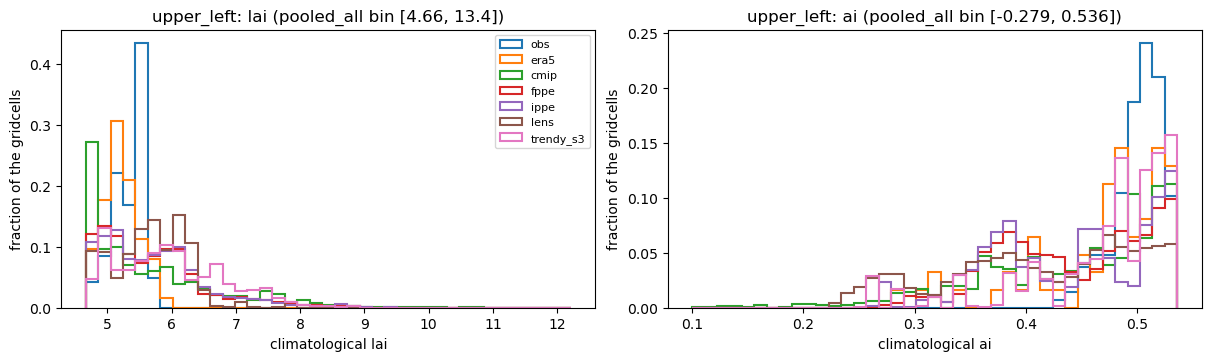

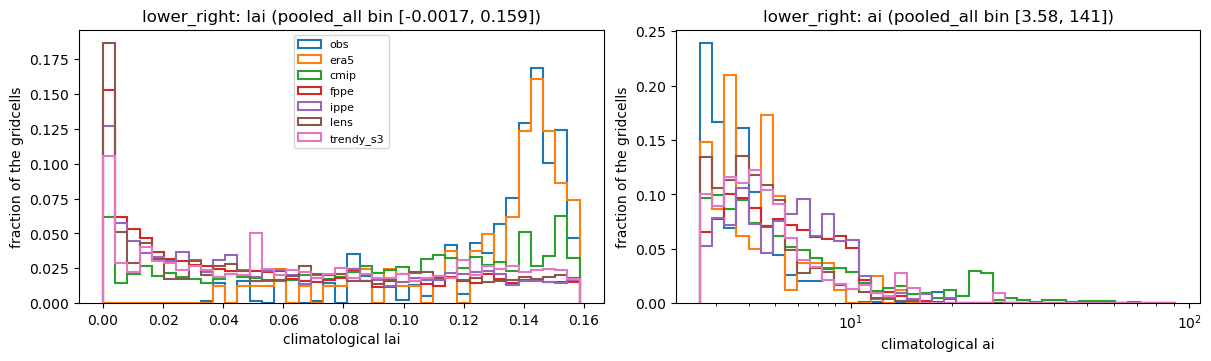

In [7]:
for corner in CORNERS:
    plot_lai_ai_hist(corner)

## 4. Where are the corner gridcells?

### Fraction of each family's members that put a gridcell in the corner
1 = every member; light gray = the rest of the common area (zoom in: the upper-left corner holds few
gridcells). The obs members share one LAI, P and Rn product (their combinations differ in ET), so the
obs map is 0 or 1.

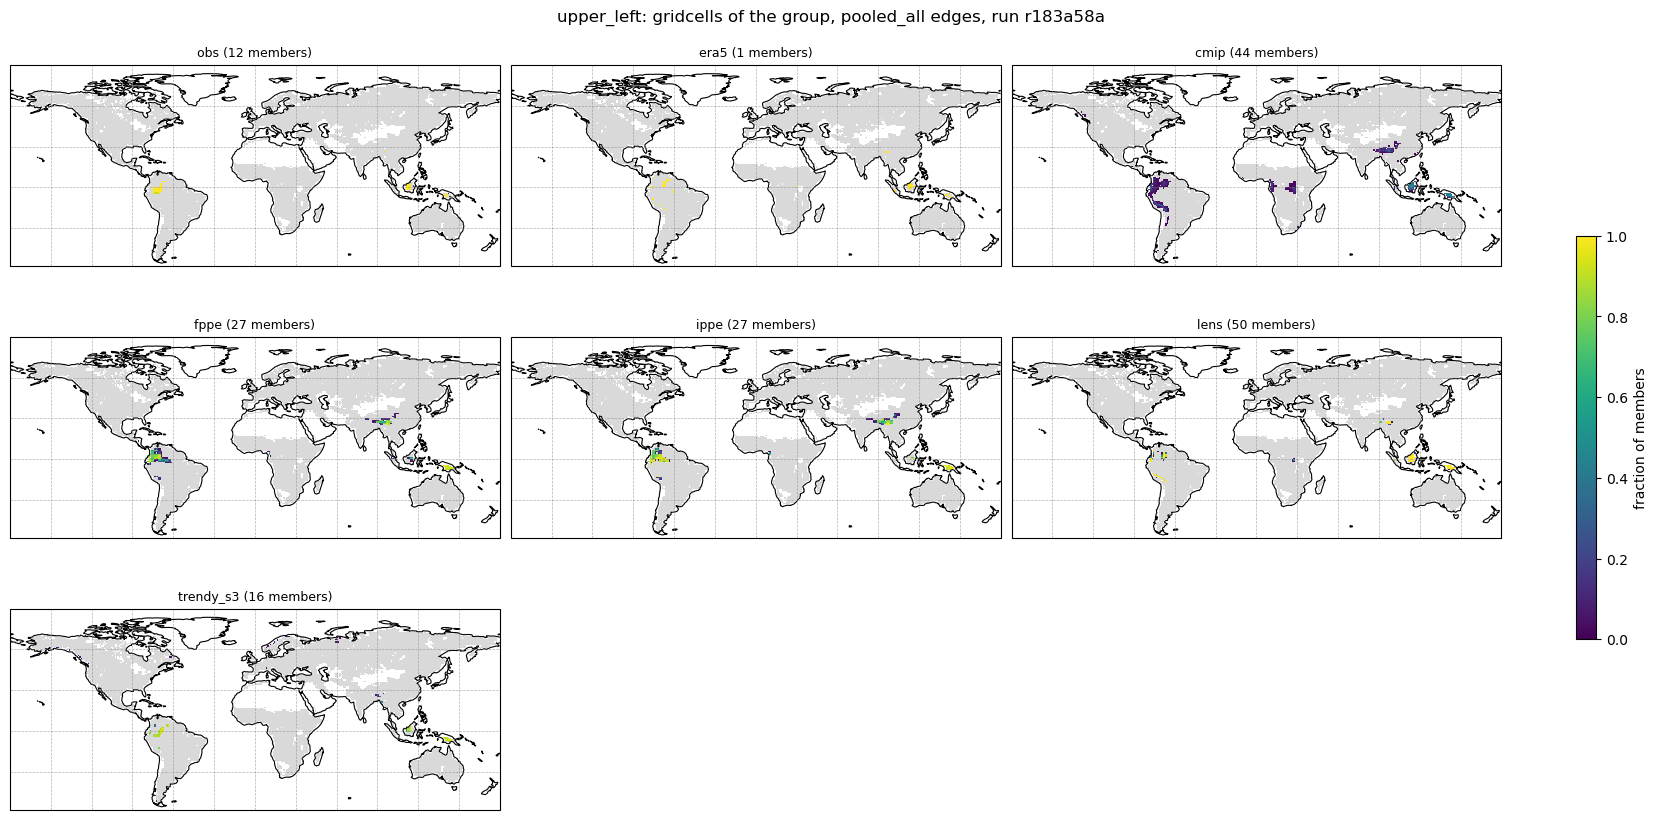

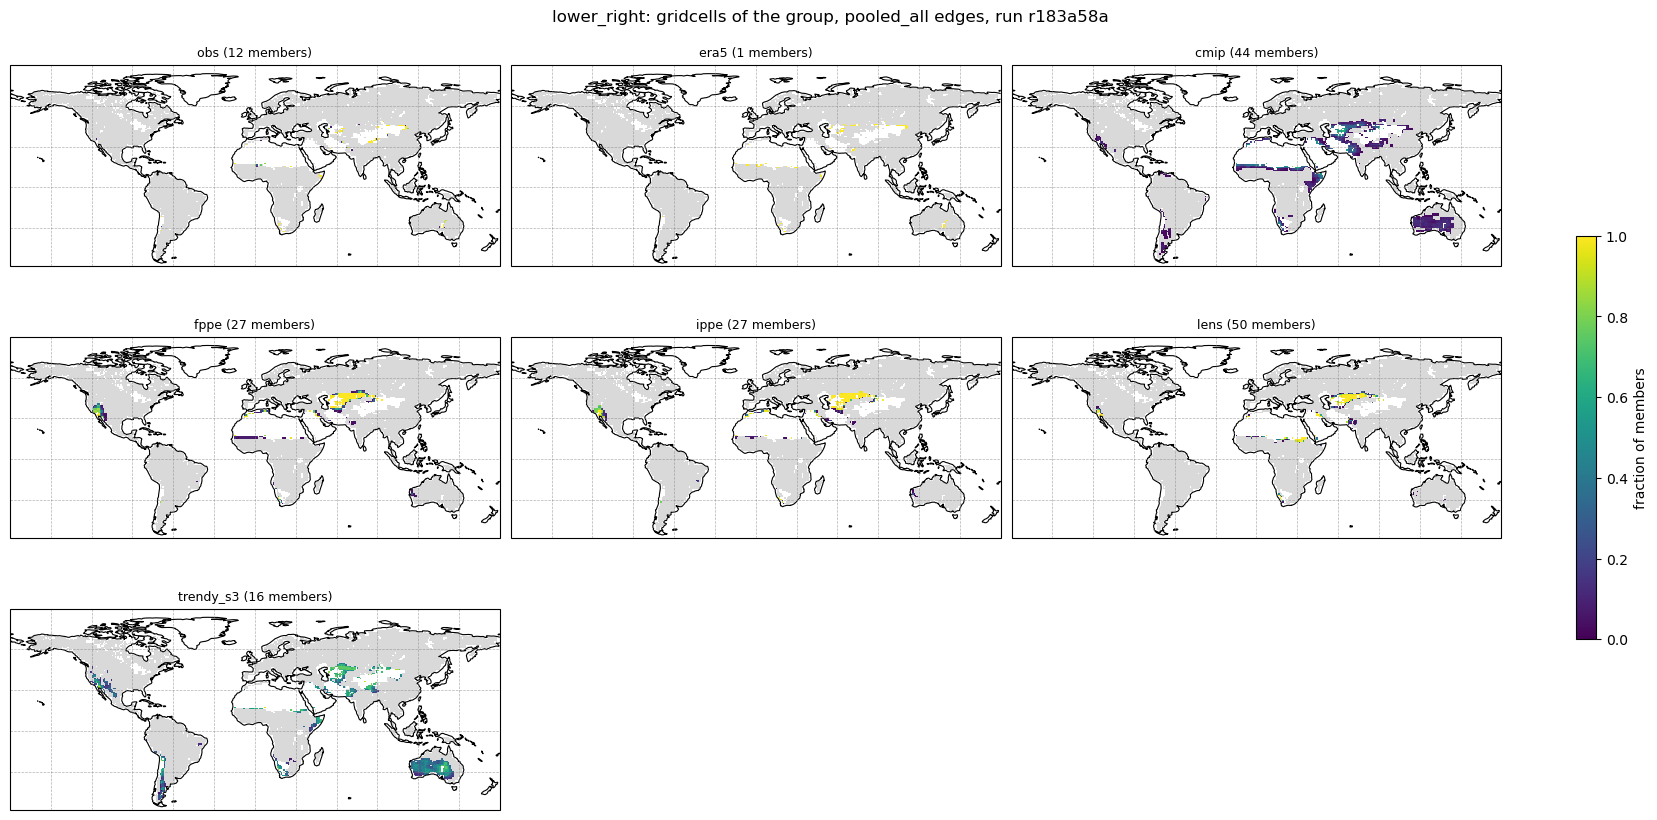

In [8]:
for corner in CORNERS:
    map_fraction(corner)

### Land area of each corner by AR6 land region

Land area [10³ km²] of the corner gridcells in each AR6 region, averaged over the members of each
family, for the regions holding most of the corner's land across families.

In [9]:
for corner in CORNERS:
    print(f"\n{corner}: land area [10^3 km2] by AR6 region, mean over members")
    display(region_table(corner))


upper_left: land area [10^3 km2] by AR6 region, mean over members


,obs,era5,cmip,fppe,ippe,lens,trendy_s3
region,,,,,,,
SEA,328,306,219,270,271,550,329
NSA,318,247,36,273,383,174,279
NWS,193,74,95,412,444,169,130
SAS,11,67,42,177,196,80,17
SAM,0,48,48,6,14,94,10
TIB,0,0,16,77,103,20,1
EAS,0,0,13,19,43,0,0
CAF,0,0,35,16,16,1,0
SEAF,0,12,13,0,0,7,0



lower_right: land area [10^3 km2] by AR6 region, mean over members


,obs,era5,cmip,fppe,ippe,lens,trendy_s3
region,,,,,,,
WCA,113,121,380,612,656,456,470
WSB,1,129,128,731,717,534,296
CAU,68,66,249,8,6,1,1234
SAH,68,142,184,69,55,149,136
NEAF,49,85,205,0,0,178,223
WNA,1,0,6,233,227,62,160
ECA,82,45,59,80,78,36,98
WSAF,43,43,56,37,41,62,166
SAS,13,44,126,4,3,51,165


## 5. ET of the corner gridcells

Histograms of the gridcell ET in each corner (climatological ET with `ET_SAMPLES = "clim"`, each
gridcell-year with `"annual"`), one panel per family, all of its members pooled (each member weighs
equally). The dashed line is the pooled mean; the text gives the number of samples and the mean of
the members' bin means. The histogram range is the 0.1-99.9th percentile of every family's samples;
values outside are counted in the end bins.

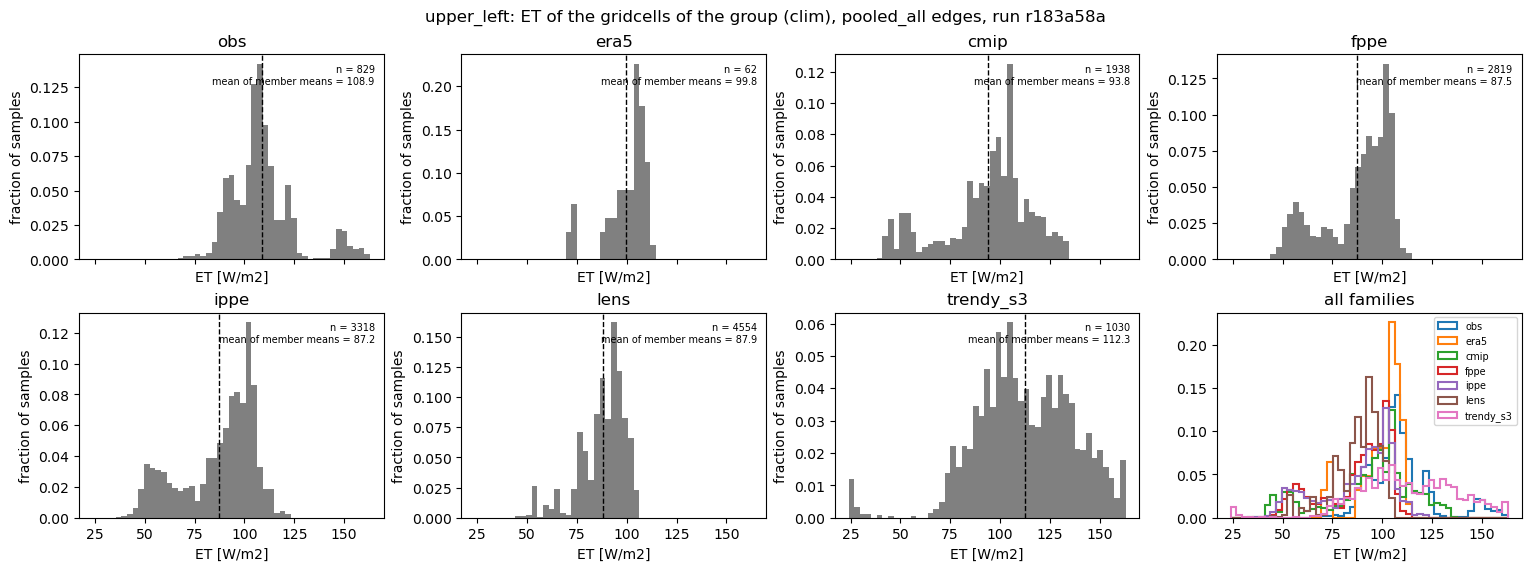

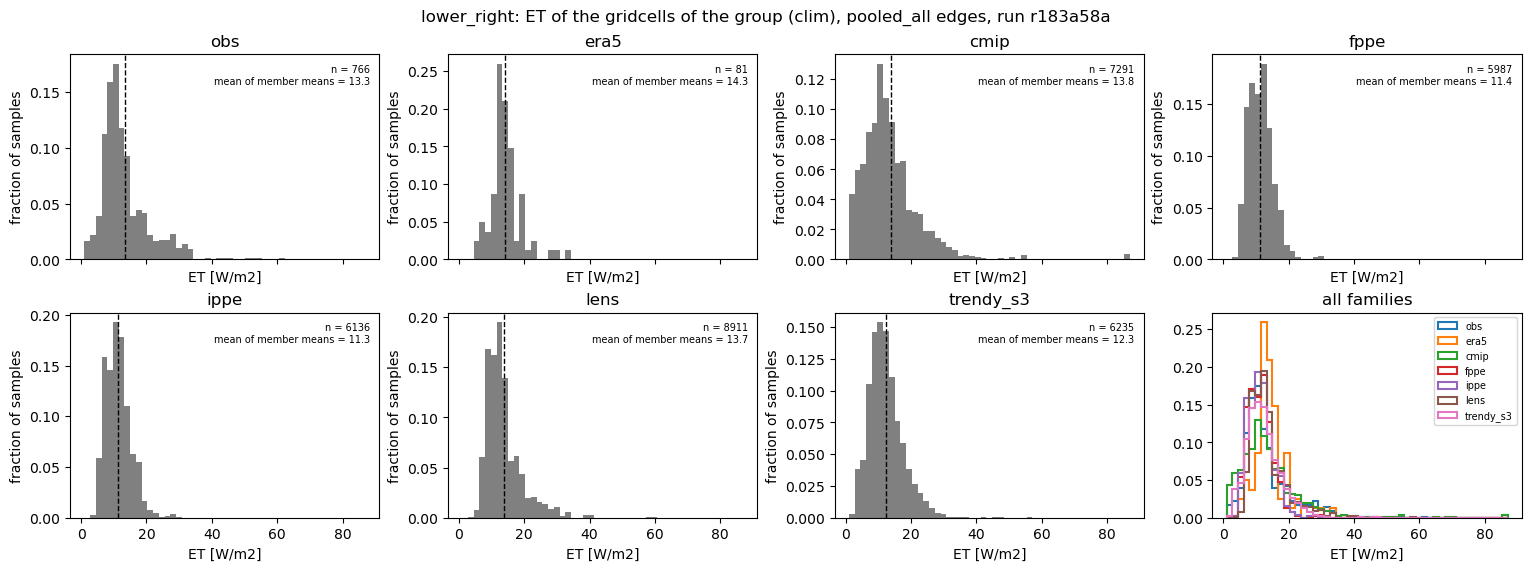

In [10]:
for corner in CORNERS:
    plot_et_hists(corner)

## 6. Per member of one family (`DETAIL_FAMILY`)

### Maps of the ET of each member's corner gridcells

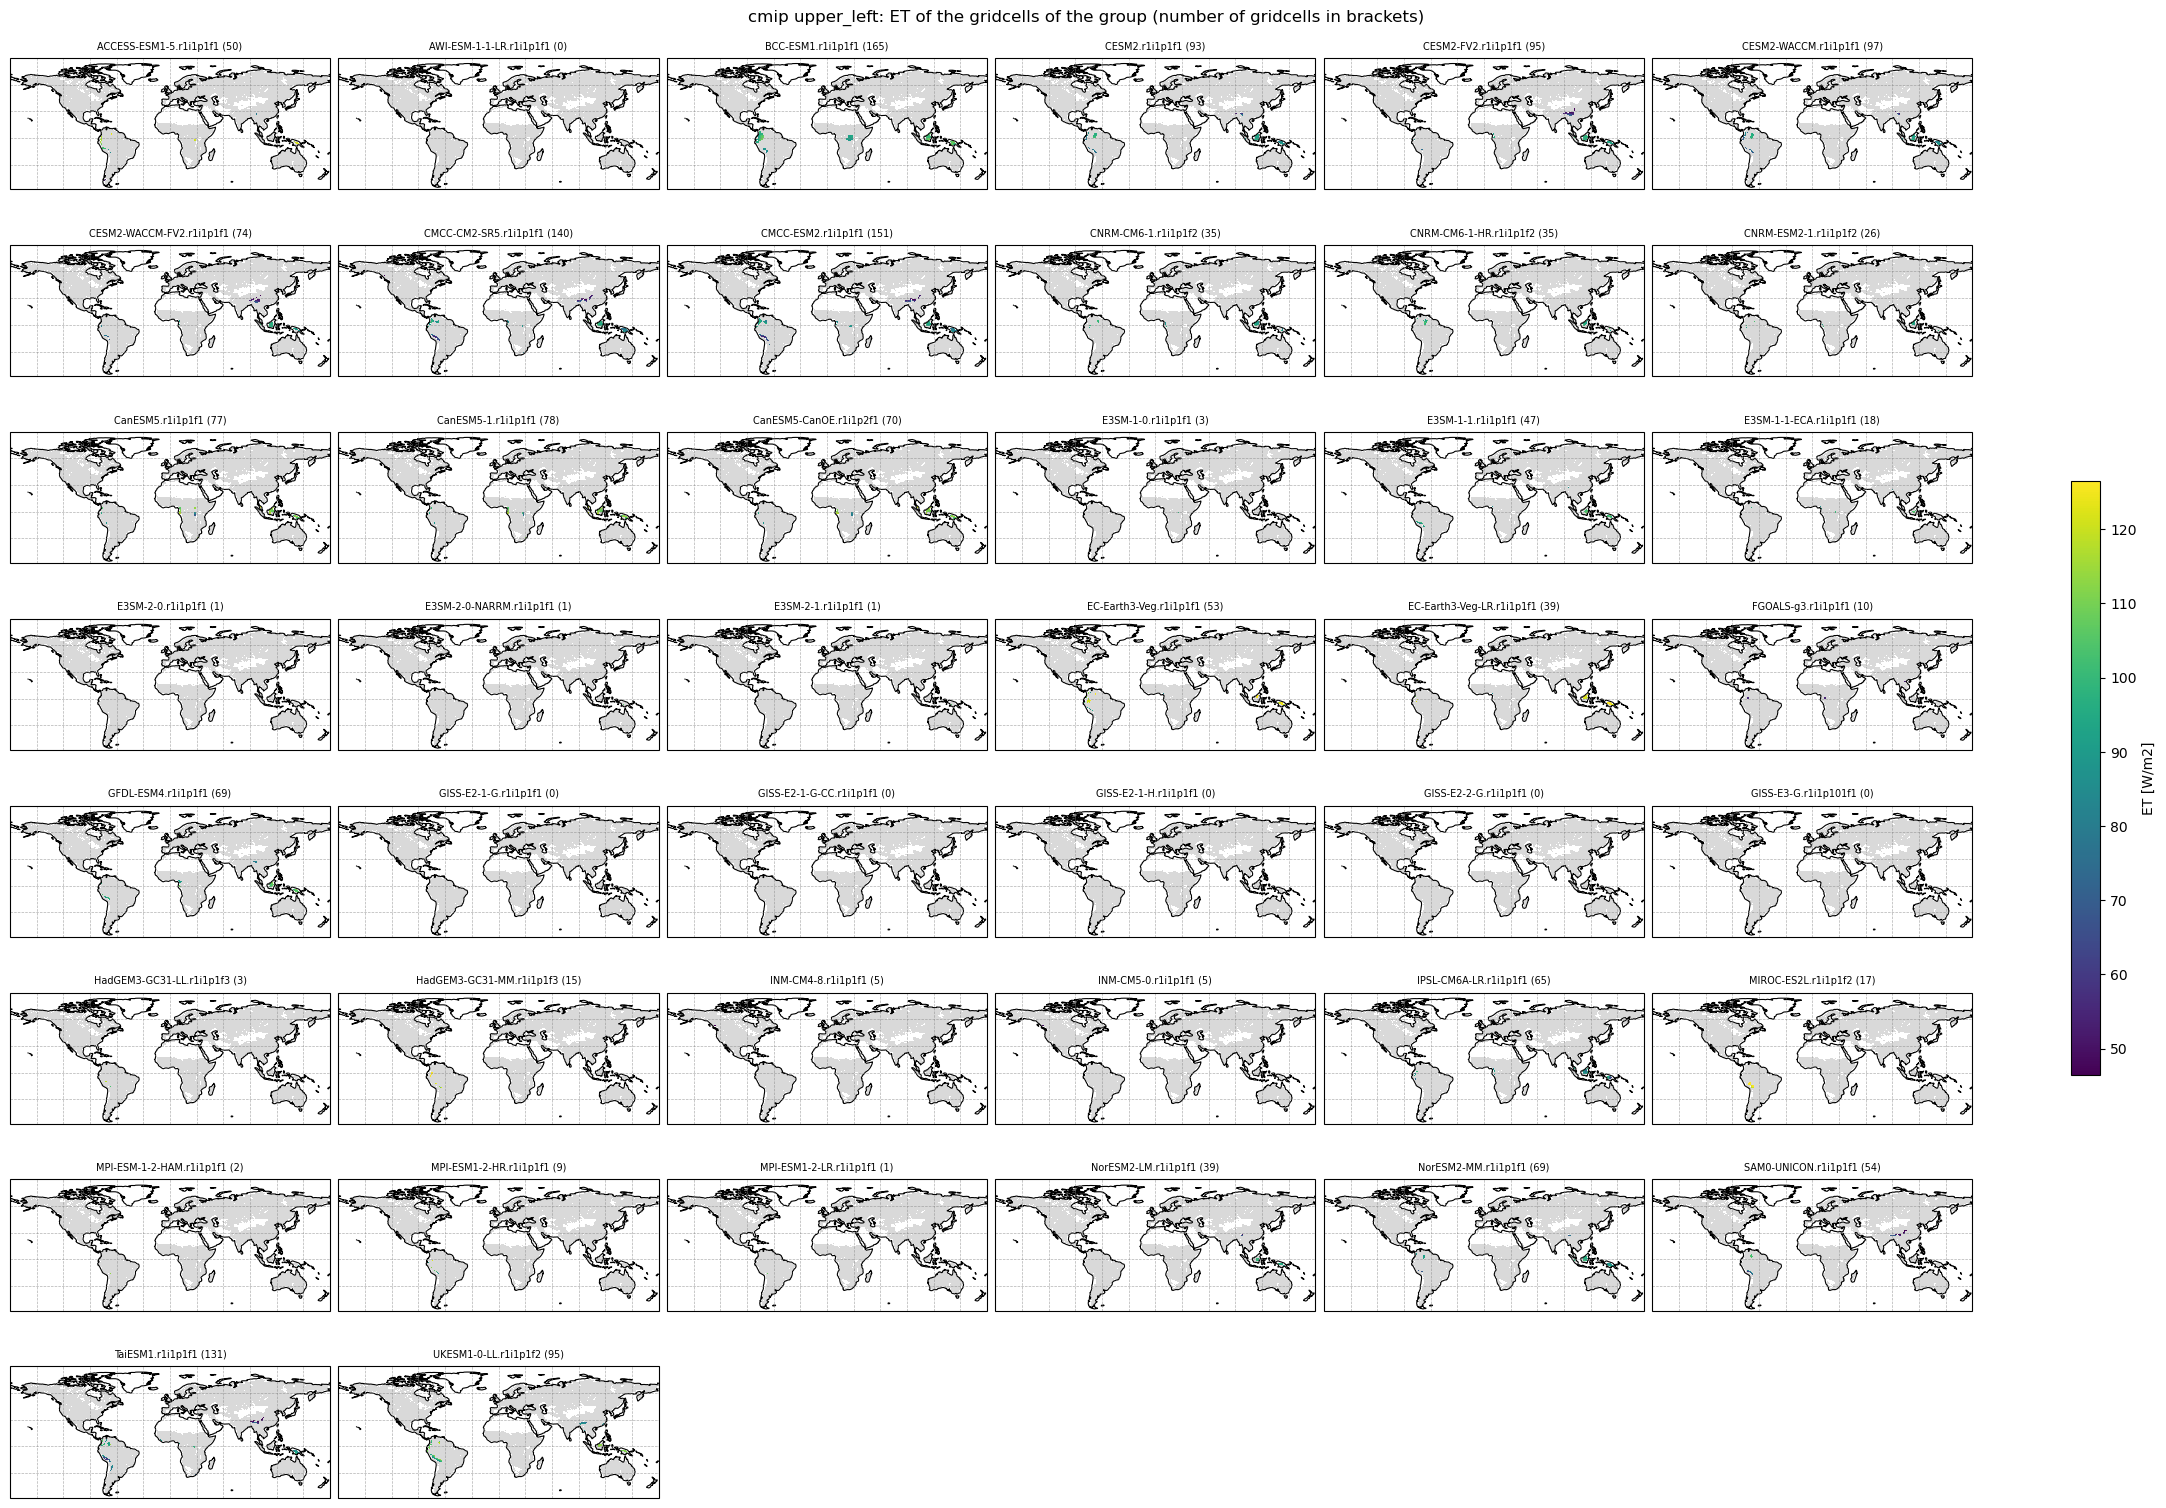

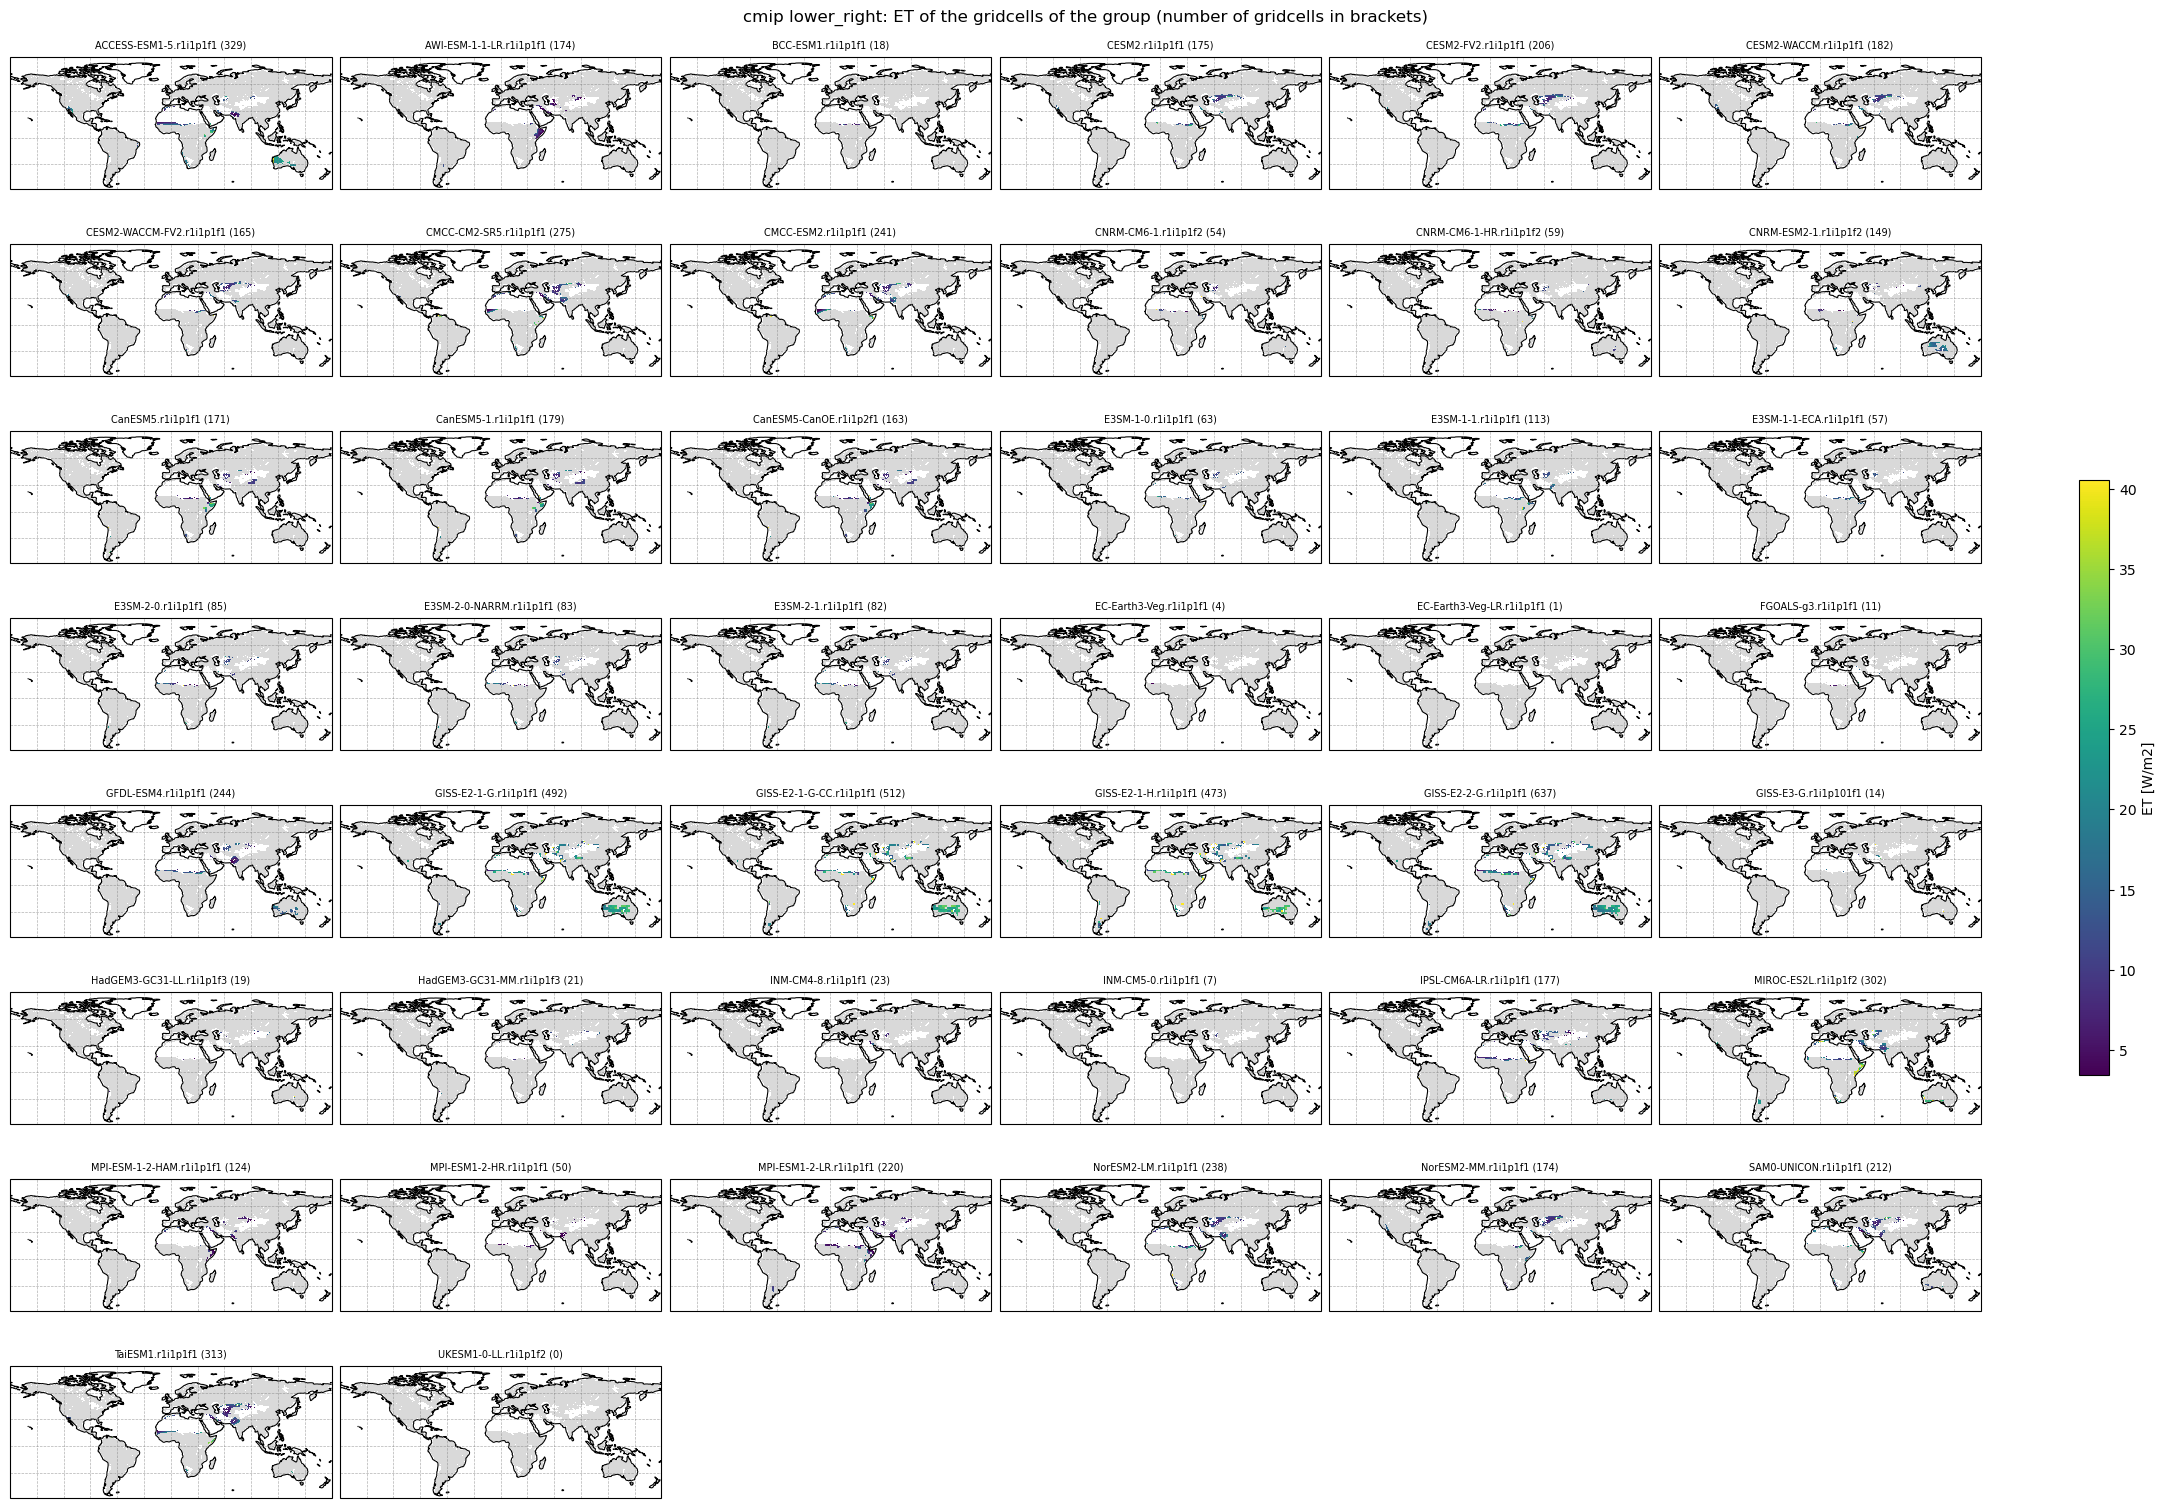

In [11]:
for corner in CORNERS:
    plot_member_maps(corner)

### ET histograms of each member's corner gridcells

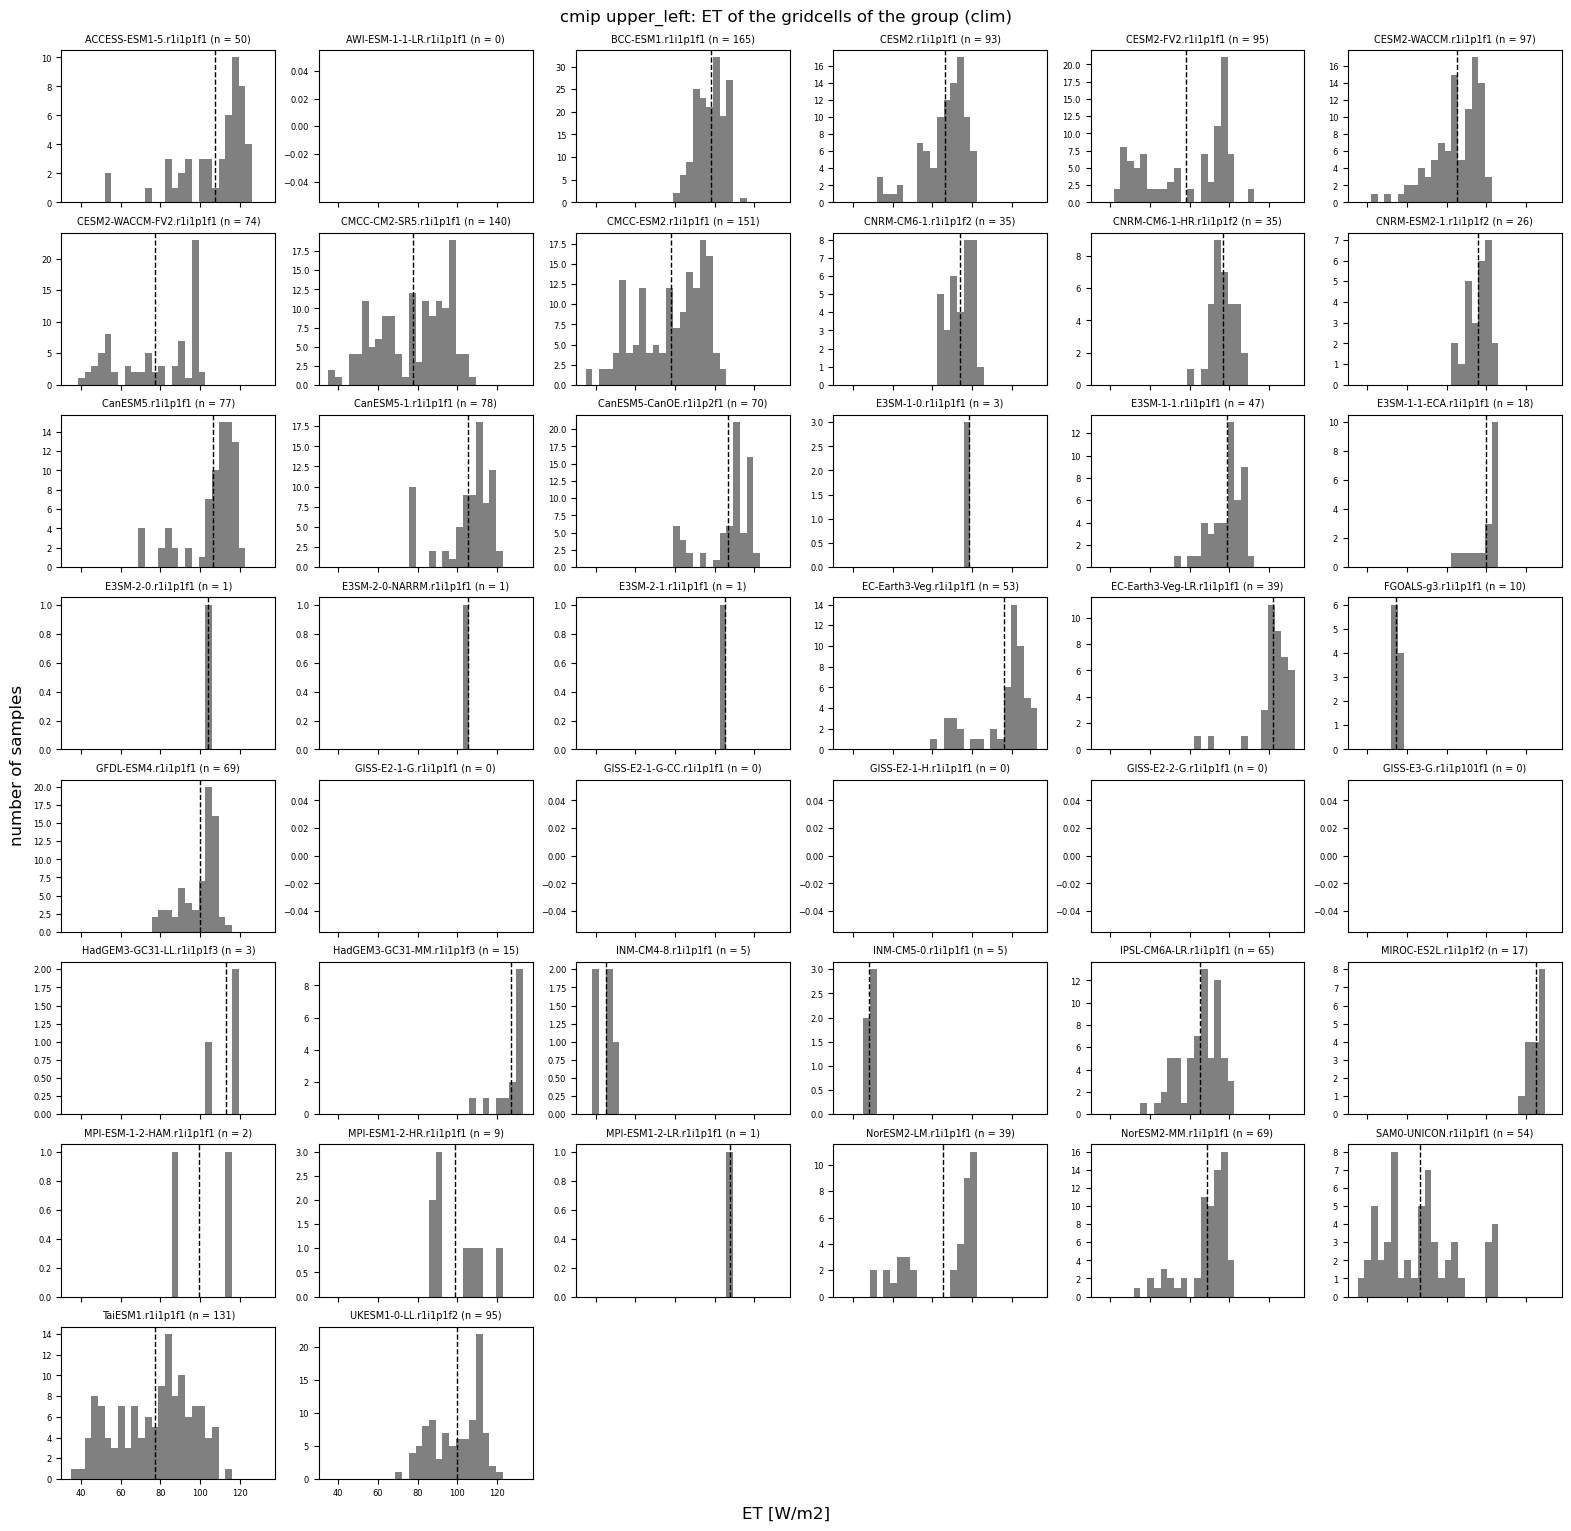

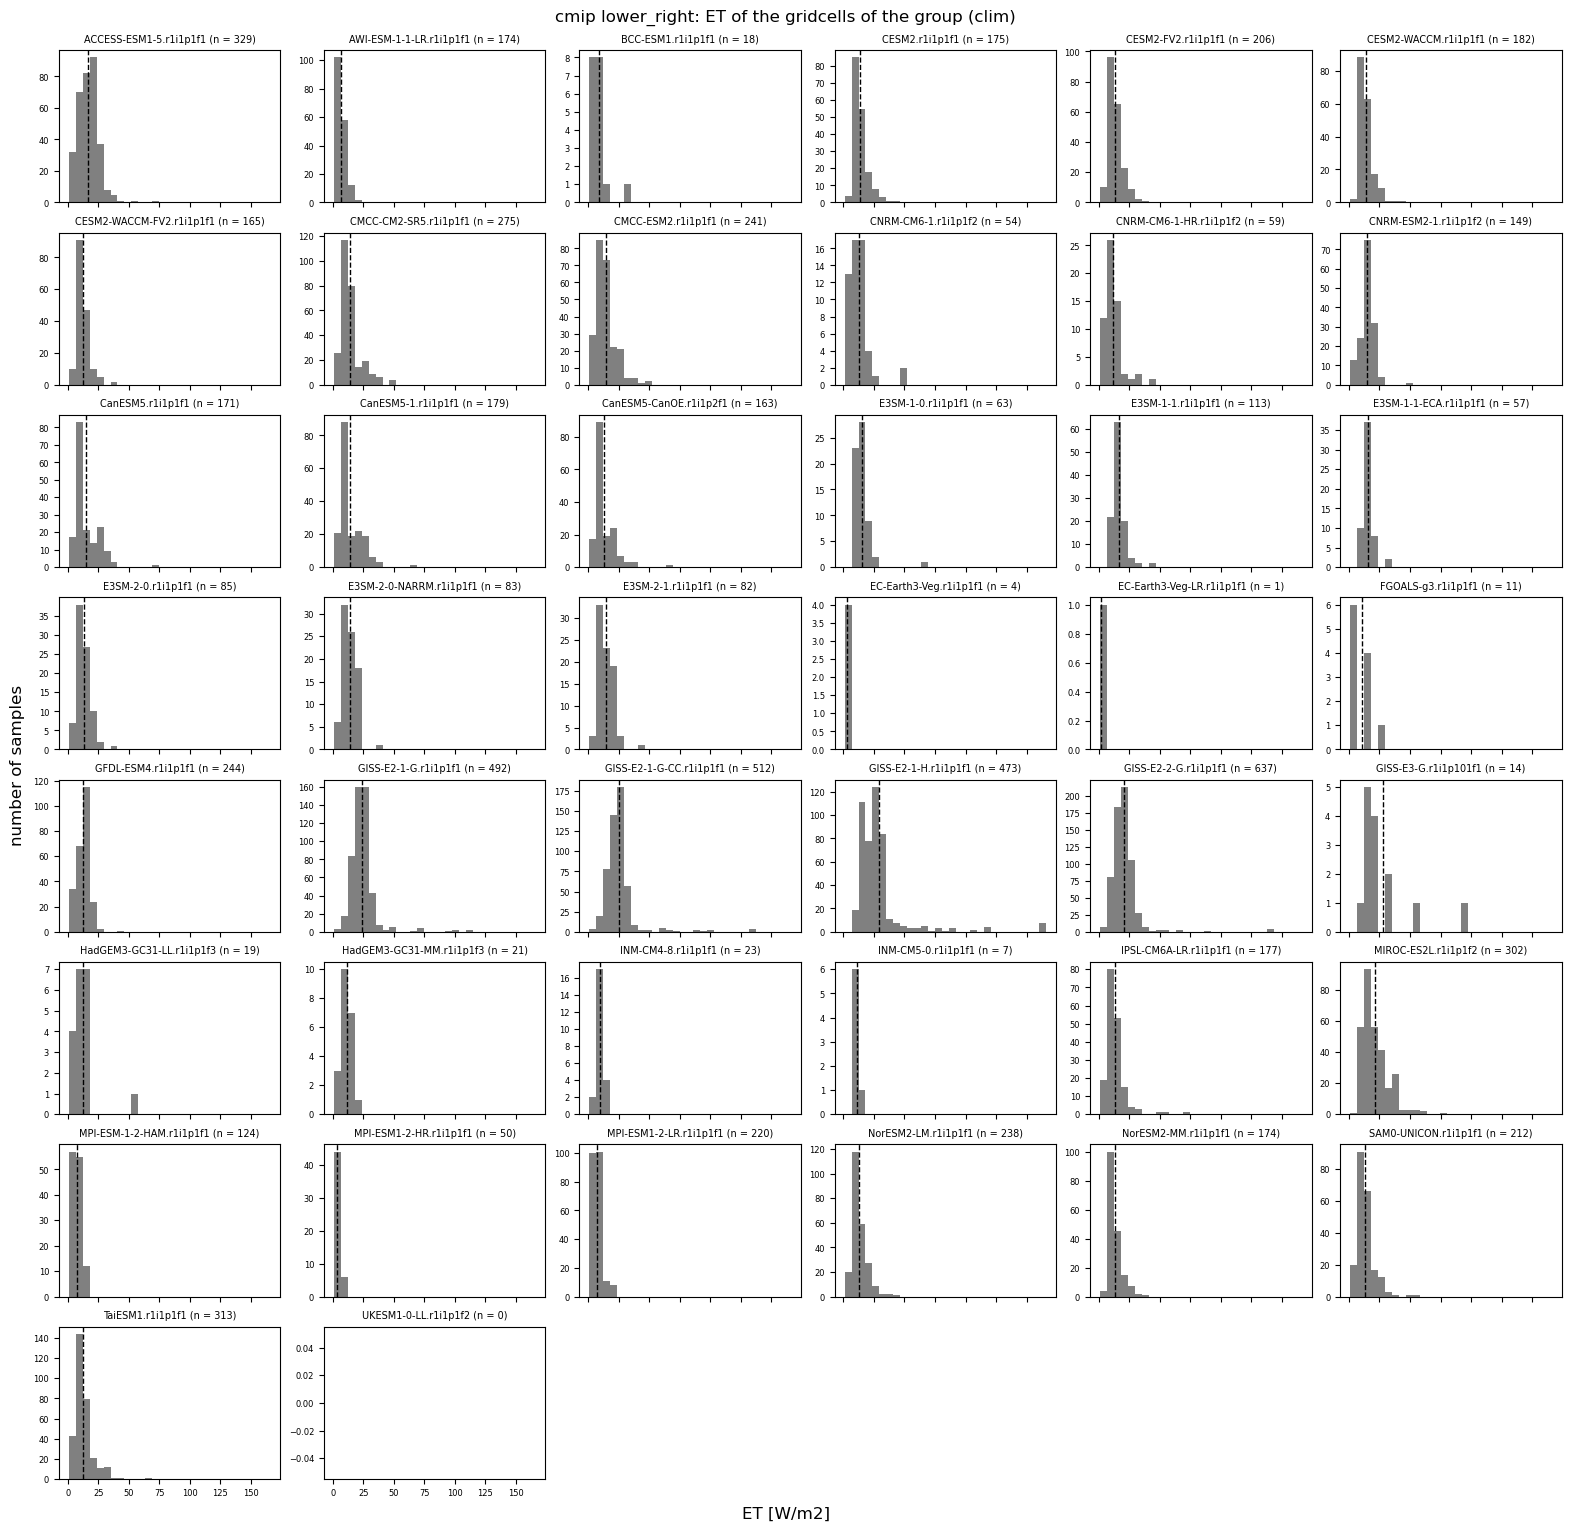

In [12]:
for corner in CORNERS:
    plot_member_hists(corner)

## 7. Dense bins near the corners

Some members pile their land into bins near a corner but not into the exact corner bin. Per member,
a bin is **dense** if it holds more than `DENSE_FACTOR` / (n_ybins × n_xbins) of the member's land
(the land fraction of `bin_area.py`), i.e. `DENSE_FACTOR` times the share of a bin if LAI and AI were
independent (1.78% for 4 × 1/225). Only dense bins inside the **region** of a corner are kept: the
`REGION_FRAC` of the bins at the corner's end of each axis (the 5 × 5 bins of the corner for 1/3 of
15 bins). The exact corner bin is part of its region, so it is selected when it is dense. Dense bins
elsewhere (along the LAI-AI diagonal ridge) are not diagnosed.

### Land fraction of each bin, and the dense bins of each member
The land fraction is recomputed from the gridcells (common area, land area weights) and checked
against the saved `land_area_frac` of `bin_area.py`.

In [21]:
def bin_land_fraction(ds: xr.Dataset) -> xr.DataArray:
    """Fraction of each member's land (common area) in each bin, (member, y_bin, x_bin): land_area_frac of bin_area.py."""
    valid = ((ds["y_bin"] >= 0) & (ds["x_bin"] >= 0) & area).transpose("member", "lat", "lon")
    lin = (ds["y_bin"] * N_XBINS + ds["x_bin"]).where(valid, 0).values
    w = land.where(valid, 0).transpose("member", "lat", "lon").values
    total = np.stack([np.bincount(l.ravel(), weights=wm.ravel(), minlength=N_YBINS * N_XBINS) for l, wm in zip(lin, w)])
    frac = (total / total.sum(axis=1, keepdims=True)).reshape(-1, N_YBINS, N_XBINS)
    return xr.DataArray(frac, dims=("member", "y_bin", "x_bin"),
                        coords={"member": ds["member"].values, "y_bin": np.arange(N_YBINS), "x_bin": np.arange(N_XBINS)},
                        name="land_frac")


def with_edge_coords(da: xr.DataArray, family: str) -> xr.DataArray:
    """Add the lower/upper edge coords of the family's bins (used by the plotting functions)."""
    y_e, x_e = bin_edges[family]
    return da.assign_coords(
        y_bin_lower=("y_bin", y_e[:-1]), y_bin_upper=("y_bin", y_e[1:]),
        x_bin_lower=("x_bin", x_e[:-1]), x_bin_upper=("x_bin", x_e[1:]),
    ).assign_attrs(y_variable="lai", x_variable="ai")


dense_min = DENSE_FACTOR / (N_YBINS * N_XBINS)
land_frac = {}  # family -> (member, y_bin, x_bin) fraction of the member's land
dense = {}      # family -> (member, y_bin, x_bin) dense, any bin
selected = {}   # family -> {corner: (member, y_bin, x_bin) dense and in the corner's region}
regions = {}    # family -> {corner: (LAI bins, AI bins) of the region}
rows = []
for family, ds in data.items():
    y_edges, x_edges = bin_edges[family]
    land_frac[family] = with_edge_coords(bin_land_fraction(ds), family)
    dense[family] = land_frac[family] > dense_min

    # Check against the saved land fraction of bin_area.py
    path = cfg.output_dir(cfg.PROC_ROOT, family, "qbin", RUN_ID) / f"{family}.land_area.qbin_{edges_kind(family)}.{RUN_ID}.nc"
    saved = xr.open_dataset(path)["land_area_frac"]
    diff = float(np.abs(land_frac[family].values - saved.transpose("member", "y_bin", "x_bin").values).max())
    assert diff < 1e-10, f"{family}: land fraction differs from {path} by {diff}"

    selected[family], regions[family] = {}, {}
    for corner, ends in CORNERS.items():
        # Region: the outer REGION_FRAC of the non-zero-width bins of each axis
        yr = corner_bins(y_edges, ends["lai"], n=max(1, round(REGION_FRAC * int((np.diff(y_edges) > 0).sum()))))
        xr_ = corner_bins(x_edges, ends["ai"], n=max(1, round(REGION_FRAC * int((np.diff(x_edges) > 0).sum()))))
        regions[family][corner] = (yr, xr_)
        sel = dense[family] & land_frac[family]["y_bin"].isin(yr) & land_frac[family]["x_bin"].isin(xr_)
        selected[family][corner] = sel

        # Gridcells of each member in its selected bins
        m = np.arange(ds.sizes["member"])[:, None, None]
        yb, xb = ds["y_bin"].values, ds["x_bin"].values
        hit = sel.values[m, np.maximum(yb, 0), np.maximum(xb, 0)] & (yb >= 0) & (xb >= 0)
        ds[f"in_dense_{corner}"] = ds["y_bin"].copy(data=hit) & area

        # Members with a dense bin in the region, and those whose dense bins miss the exact corner bin
        cy, cx = int(bounds[family][corner]["y_bins"][-1 if ends["lai"] == "high" else 0]), \
                 int(bounds[family][corner]["x_bins"][-1 if ends["ai"] == "high" else 0])
        any_sel = sel.any(("y_bin", "x_bin"))
        corner_dense = sel.isel(y_bin=cy, x_bin=cx)
        n_sel = sel.sum(("y_bin", "x_bin"))
        rows.append({
            "corner": corner, "family": family, "members": ds.sizes["member"],
            "with_dense_bins": int(any_sel.sum()), "corner_bin_dense": int(corner_dense.sum()),
            "dense_but_not_corner_bin": int((any_sel & ~corner_dense).sum()),
            "dense_bins_median": float(n_sel.median()), "dense_bins_max": int(n_sel.max()),
            "pct_land_median": float(100 * land_frac[family].where(sel).sum(("y_bin", "x_bin")).median()),
        })
print(f"dense: > {100 * dense_min:.2f}% of the member's land; land fraction matches bin_area.py for every family")
display(pd.DataFrame(rows).set_index(["corner", "family"]).round(2))

dense: > 1.78% of the member's land; land fraction matches bin_area.py for every family


,,members,with_dense_bins,corner_bin_dense,dense_but_not_corner_bin,dense_bins_median,dense_bins_max,pct_land_median
corner,family,,,,,,,
upper_left,obs,12,0,0,0,0.0,0,0.00
lower_right,obs,12,12,0,12,3.0,3,9.17
upper_left,era5,1,1,0,1,1.0,1,2.74
lower_right,era5,1,1,0,1,3.0,3,9.34
upper_left,cmip,44,18,3,15,0.0,9,0.00
lower_right,cmip,44,37,23,14,2.0,5,4.72
upper_left,fppe,27,24,4,20,2.0,7,4.28
lower_right,fppe,27,24,24,0,2.0,5,3.95
upper_left,ippe,27,25,11,14,2.0,7,4.61


### Where the dense bins are in LAI-aridity space

Per family, the fraction of its members for which each bin is dense (anywhere in the space). The red
outlines are the corner regions: the dense bins inside them are the ones diagnosed below.

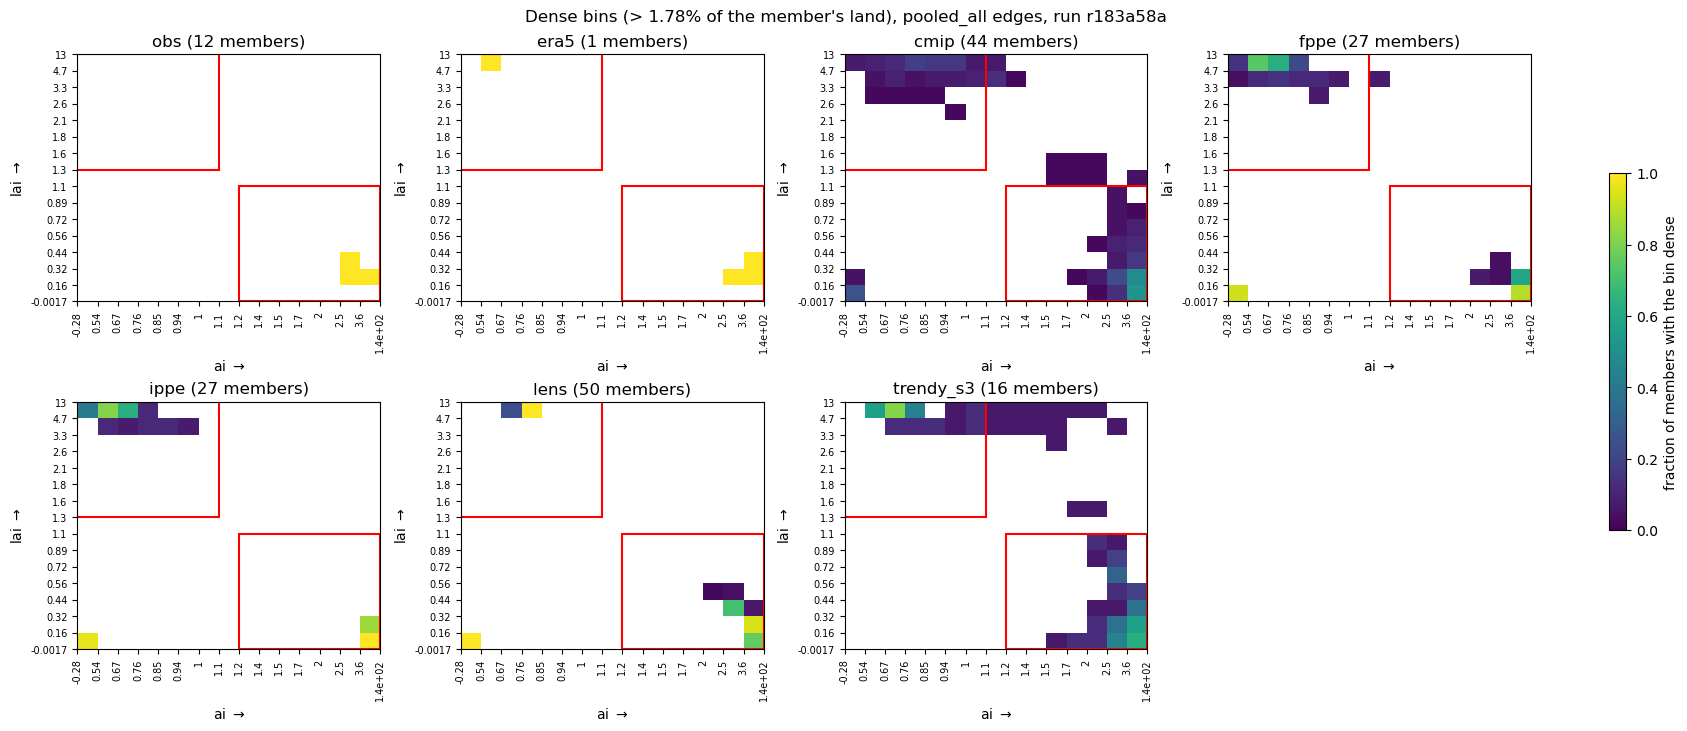

In [22]:
def outline_regions(ax, family: str):
    """Red rectangles around the corner regions, in bin index units."""
    for yr, xr_ in regions[family].values():
        ax.add_patch(Rectangle((xr_.min() - 0.5, yr.min() - 0.5), xr_.max() - xr_.min() + 1, yr.max() - yr.min() + 1,
                               fill=False, edgecolor="r", lw=1.5))


fig, axs = plotting.facets(len(data), ncols=4, panel_size=(4.2, 3.6))
for ax, family in zip(axs, data):
    fr = binning.drop_zero_width_bins(dense[family].mean("member"))
    plotting.plot_bin_field(fr.where(fr > 0), ax=ax, cmap="viridis", vmin=0, vmax=1, add_colorbar=False,
                            title=f"{family} ({data[family].sizes['member']} members)")
    outline_regions(ax, family)
fig.colorbar(axs[0].collections[0], ax=axs, label="fraction of members with the bin dense", shrink=0.6)
fig.suptitle(f"Dense bins (> {100 * dense_min:.2f}% of the member's land), {EDGES} edges, run {RUN_ID}")
plt.show()

Per member of `DETAIL_FAMILY`: the land fraction of every bin (as in the `bin_area.py` figures), with
the selected dense bins (dense and in a corner region) hatched.

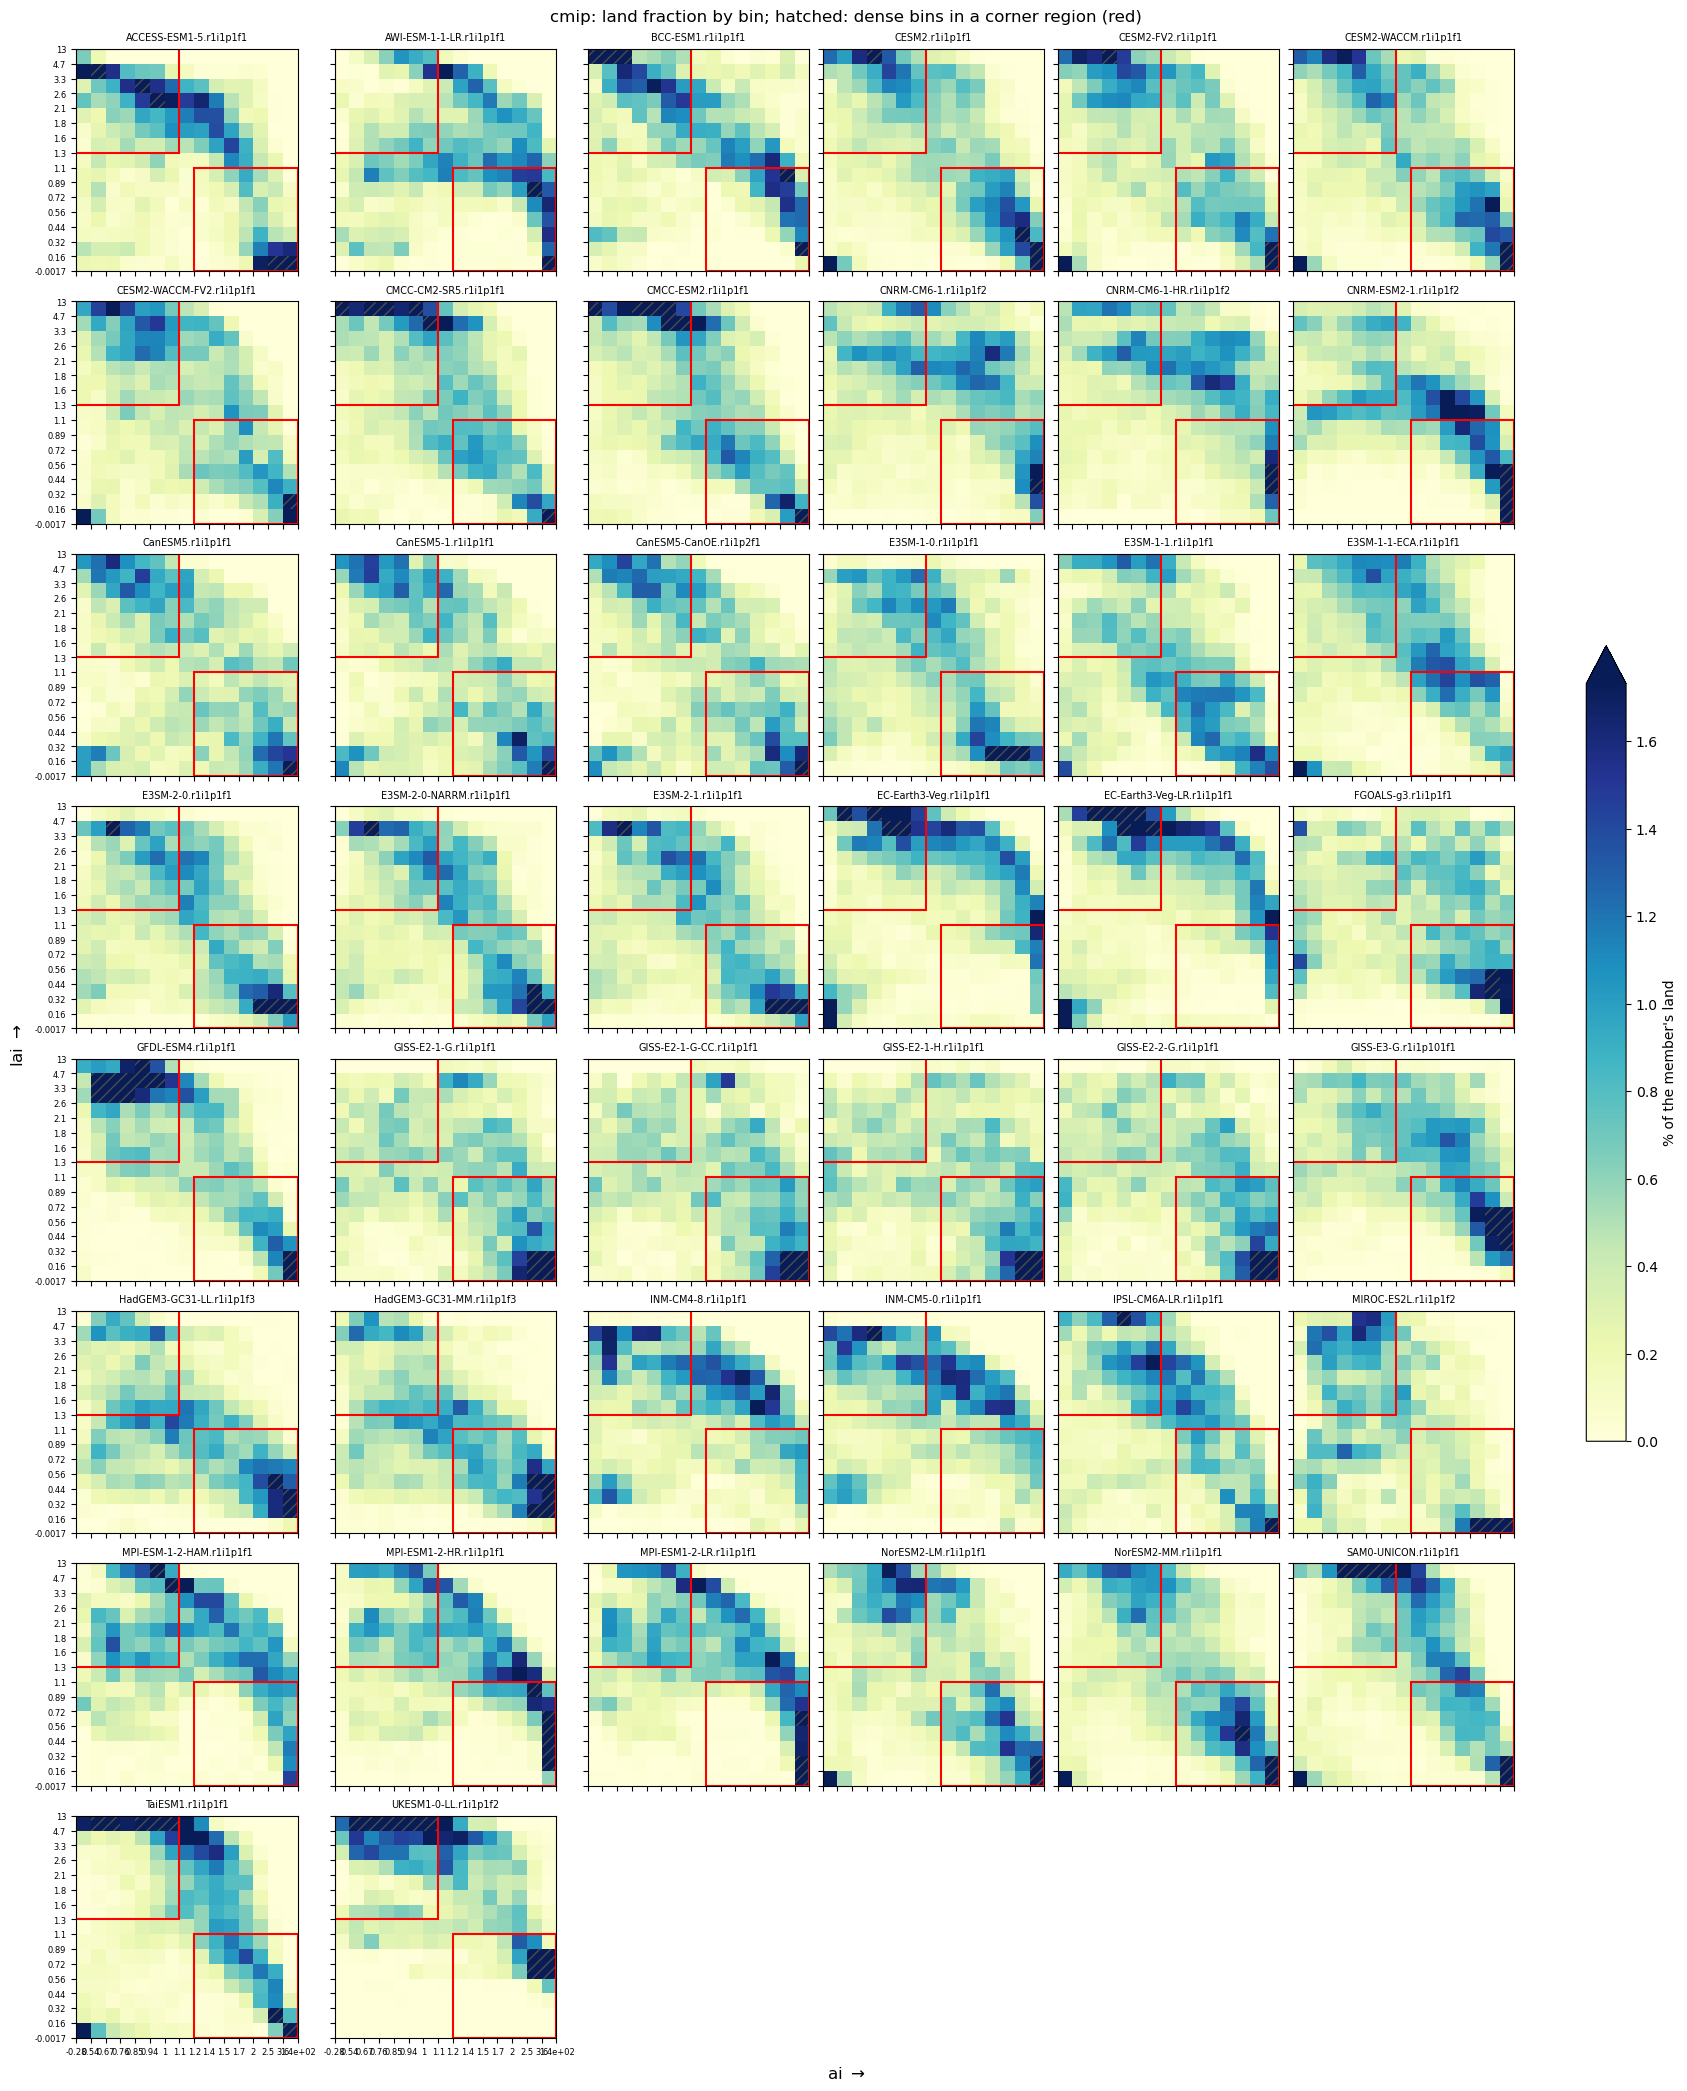

In [23]:
def plot_member_land_frac(family: str = DETAIL_FAMILY):
    lf = binning.drop_zero_width_bins(100 * land_frac[family])
    sel = binning.drop_zero_width_bins(with_edge_coords(
        sum(s.astype(int) for s in selected[family].values()) > 0, family))
    vmax = float(lf.quantile(0.98))
    fig, axs = plotting.facets(lf.sizes["member"], ncols=6, panel_size=(2.8, 2.6), sharex=True, sharey=True)
    for ax, member in zip(axs, lf["member"].values):
        plotting.plot_bin_field(lf.sel(member=member), ax=ax, hatch=sel.sel(member=member), edge_ticks=False,
                                cmap="YlGnBu", vmin=0, vmax=vmax, add_colorbar=False)
        outline_regions(ax, family)
        ax.set(xlabel="", ylabel="")
        ax.set_title(member, fontsize=7)
    # Axes are shared, so the edge ticks of the first panel apply to every panel
    plotting.set_edge_ticks(axs[0], lf, "{:.2g}")
    for ax in axs:
        ax.tick_params(labelsize=6)
    fig.colorbar(axs[0].collections[0], ax=axs, label="% of the member's land", shrink=0.4, extend="max")
    fig.supxlabel("ai $\\rightarrow$")
    fig.supylabel("lai $\\rightarrow$")
    fig.suptitle(f"{family}: land fraction by bin; hatched: dense bins in a corner region (red)")
    plt.show()


plot_member_land_frac()

### Diagnosis of the gridcells in the dense bins

The same diagnostics as sections 3-6, for the gridcells of each member's selected dense bins
(groups `dense_upper_left`, `dense_lower_right`). Members without a dense bin in a region have no
gridcells in its group (`members_none`).

members  members_none  bins_median  bins_max  \
group             family                                                    
dense_upper_left  obs             12            12          0.0         0   
                  era5             1             0          1.0         1   
                  cmip            44            26          0.0         9   
                  fppe            27             3          2.0         7   
                  ippe            27             2          2.0         7   
                  lens            50             0          1.0         2   
                  trendy_s3       16             2          2.0         9   
dense_lower_right obs             12             0          3.0         3   
                  era5             1             0          3.0         3   
                  cmip            44             7          2.0         5   
                  fppe            27             3          2.0         5   
                  ippe            27             0          2.0         2   
                  lens            50             0          3.0         4   
                  trendy_s3       16             2          4.0         7   

                             cells_median  cells_min  cells_max  \
group             family                                          
dense_upper_left  obs                 0.0          0          0   
                  era5              202.0        202        202   
                  cmip                0.0          0       2348   
                  fppe              321.0          0       1525   
                  ippe              344.0          0       1460   
                  lens              156.0        135        304   
                  trendy_s3         313.0          0       2180   
dense_lower_right obs               806.0        774        839   
                  era5              809.0        809        809   
                  cmip              393.5          0       1323   
                  fppe              368.0          0       1171   
                  ippe              393.0        187        433   
                  lens              503.5        162        731   
                  trendy_s3        1154.5          0       2614   

                             pct_land_median  pct_land_min  pct_land_max  
group             family                                                  
dense_upper_left  obs                   0.00          0.00          0.00  
                  era5                  2.74          2.74          2.74  
                  cmip                  0.00          0.00         19.88  
                  fppe                  4.28          0.00         17.22  
                  ippe                  4.61          0.00         16.46  
                  lens                  2.09          1.81          4.06  
                  trendy_s3             4.23          0.00         21.84  
dense_lower_right obs                   9.17          8.84          9.52  
                  era5                  9.34          9.34          9.34  
                  cmip                  4.72          0.00         15.37  
                  fppe                  3.95          0.00         12.98  
                  ippe                  4.24          1.87          4.70  
                  lens                  5.85          1.80          8.70  
                  trendy_s3            13.07          0.00         28.64

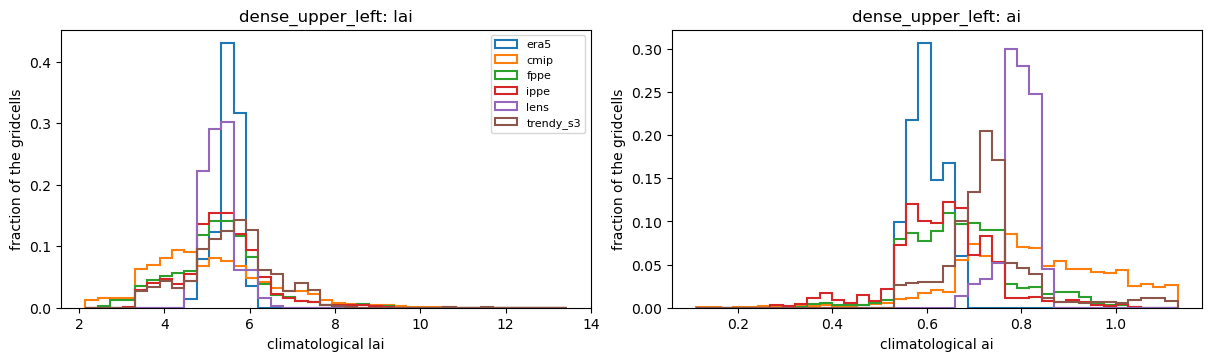

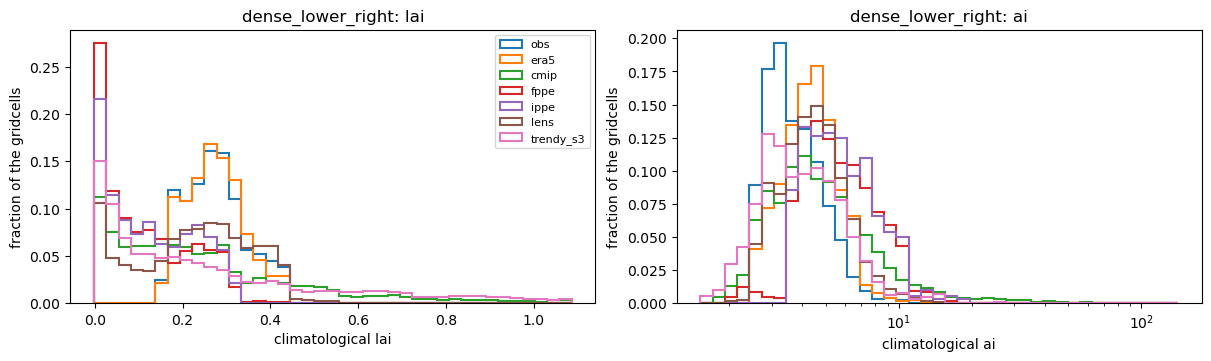

In [24]:
DENSE_GROUPS = [f"dense_{corner}" for corner in CORNERS]
display(summary_table(DENSE_GROUPS))
for group in DENSE_GROUPS:
    plot_lai_ai_hist(group)

#### Where are the gridcells of the dense bins?

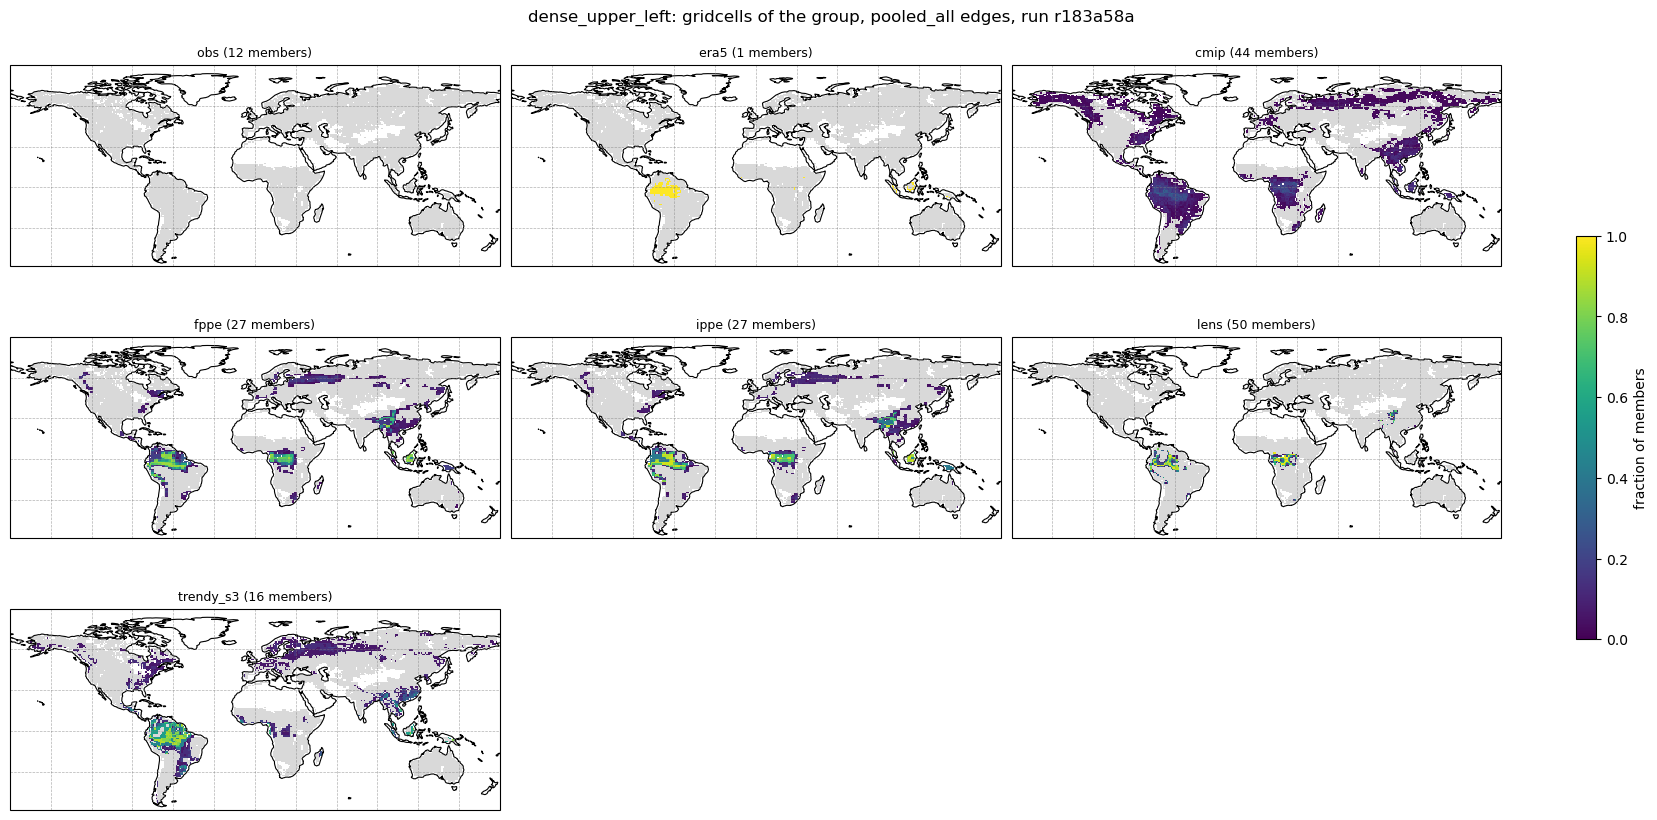


dense_upper_left: land area [10^3 km2] by AR6 region, mean over members


,obs,era5,cmip,fppe,ippe,lens,trendy_s3
region,,,,,,,
NSA,0,1678,515,1646,1577,802,2104
CAF,0,0,418,983,1004,834,180
NWS,0,457,203,440,554,304,481
SEA,0,284,148,377,456,4,312
SAM,0,24,254,141,131,38,677
EAS,0,0,205,288,277,89,302
SAS,0,0,48,201,249,17,141
TIB,0,0,16,131,144,59,20
SES,0,0,103,38,19,21,175


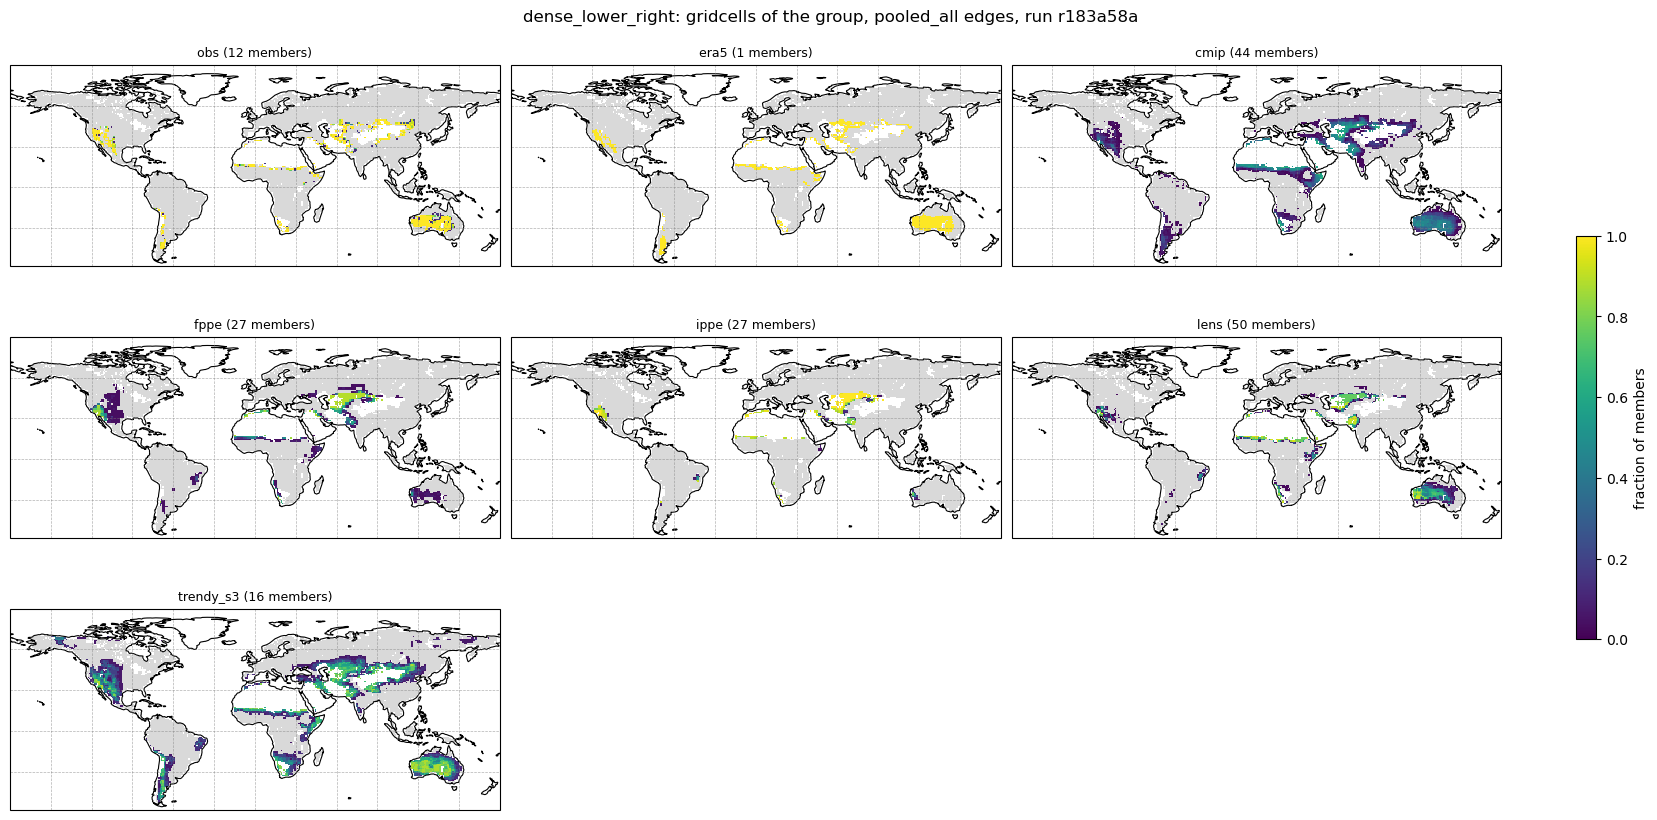


dense_lower_right: land area [10^3 km2] by AR6 region, mean over members


,obs,era5,cmip,fppe,ippe,lens,trendy_s3
region,,,,,,,
CAU,2447,2886,1205,111,70,1397,2447
WCA,984,904,745,840,1052,717,1176
WSB,332,478,396,705,759,446,747
WNA,714,459,118,337,303,115,697
SAH,388,428,320,235,351,463,398
NEAF,328,524,486,52,6,281,617
NCA,481,395,150,190,236,105,552
SAS,119,154,277,138,258,375,352
WSAF,295,229,183,108,111,184,545


In [25]:
for group in DENSE_GROUPS:
    map_fraction(group)
    print(f"\n{group}: land area [10^3 km2] by AR6 region, mean over members")
    display(region_table(group))

#### ET of the gridcells of the dense bins

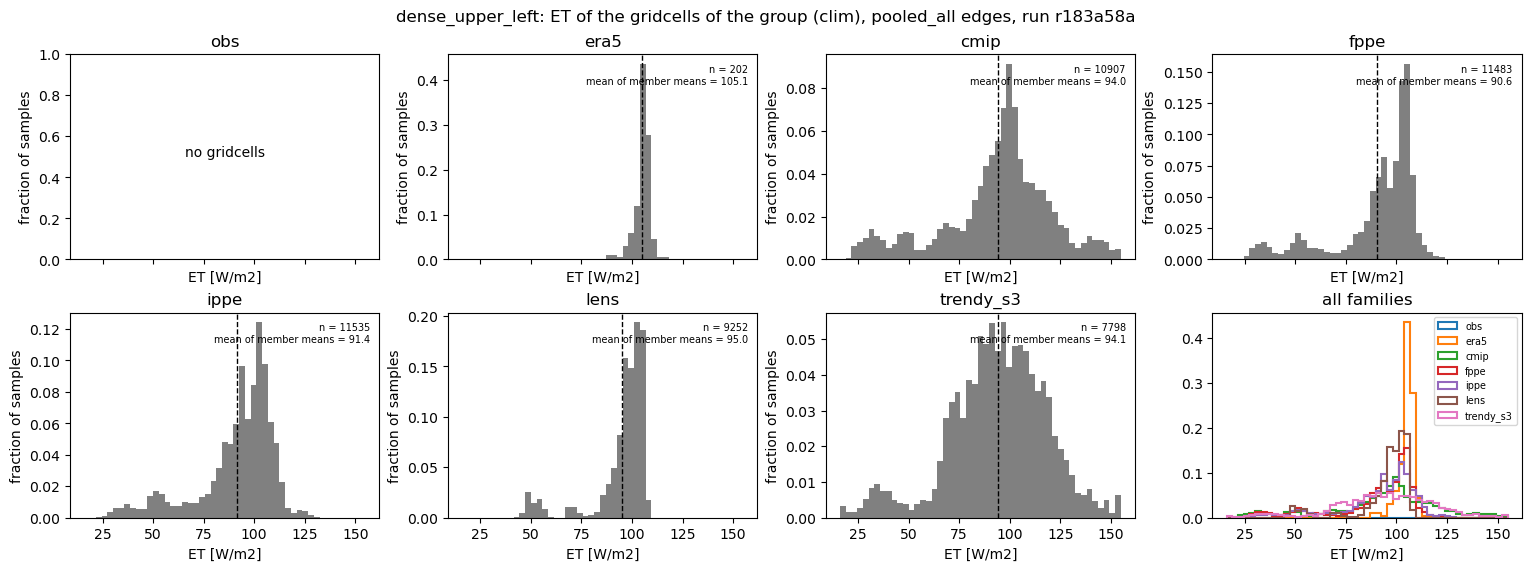

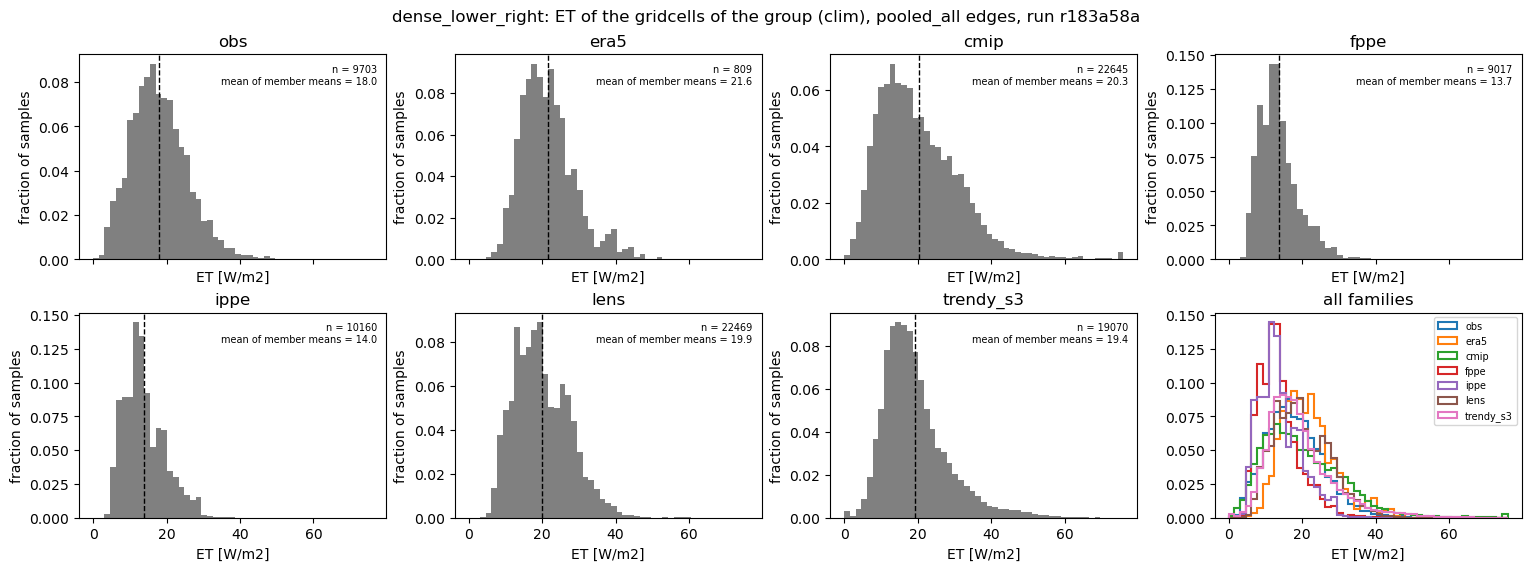

In [26]:
for group in DENSE_GROUPS:
    plot_et_hists(group)

#### Per member of `DETAIL_FAMILY`

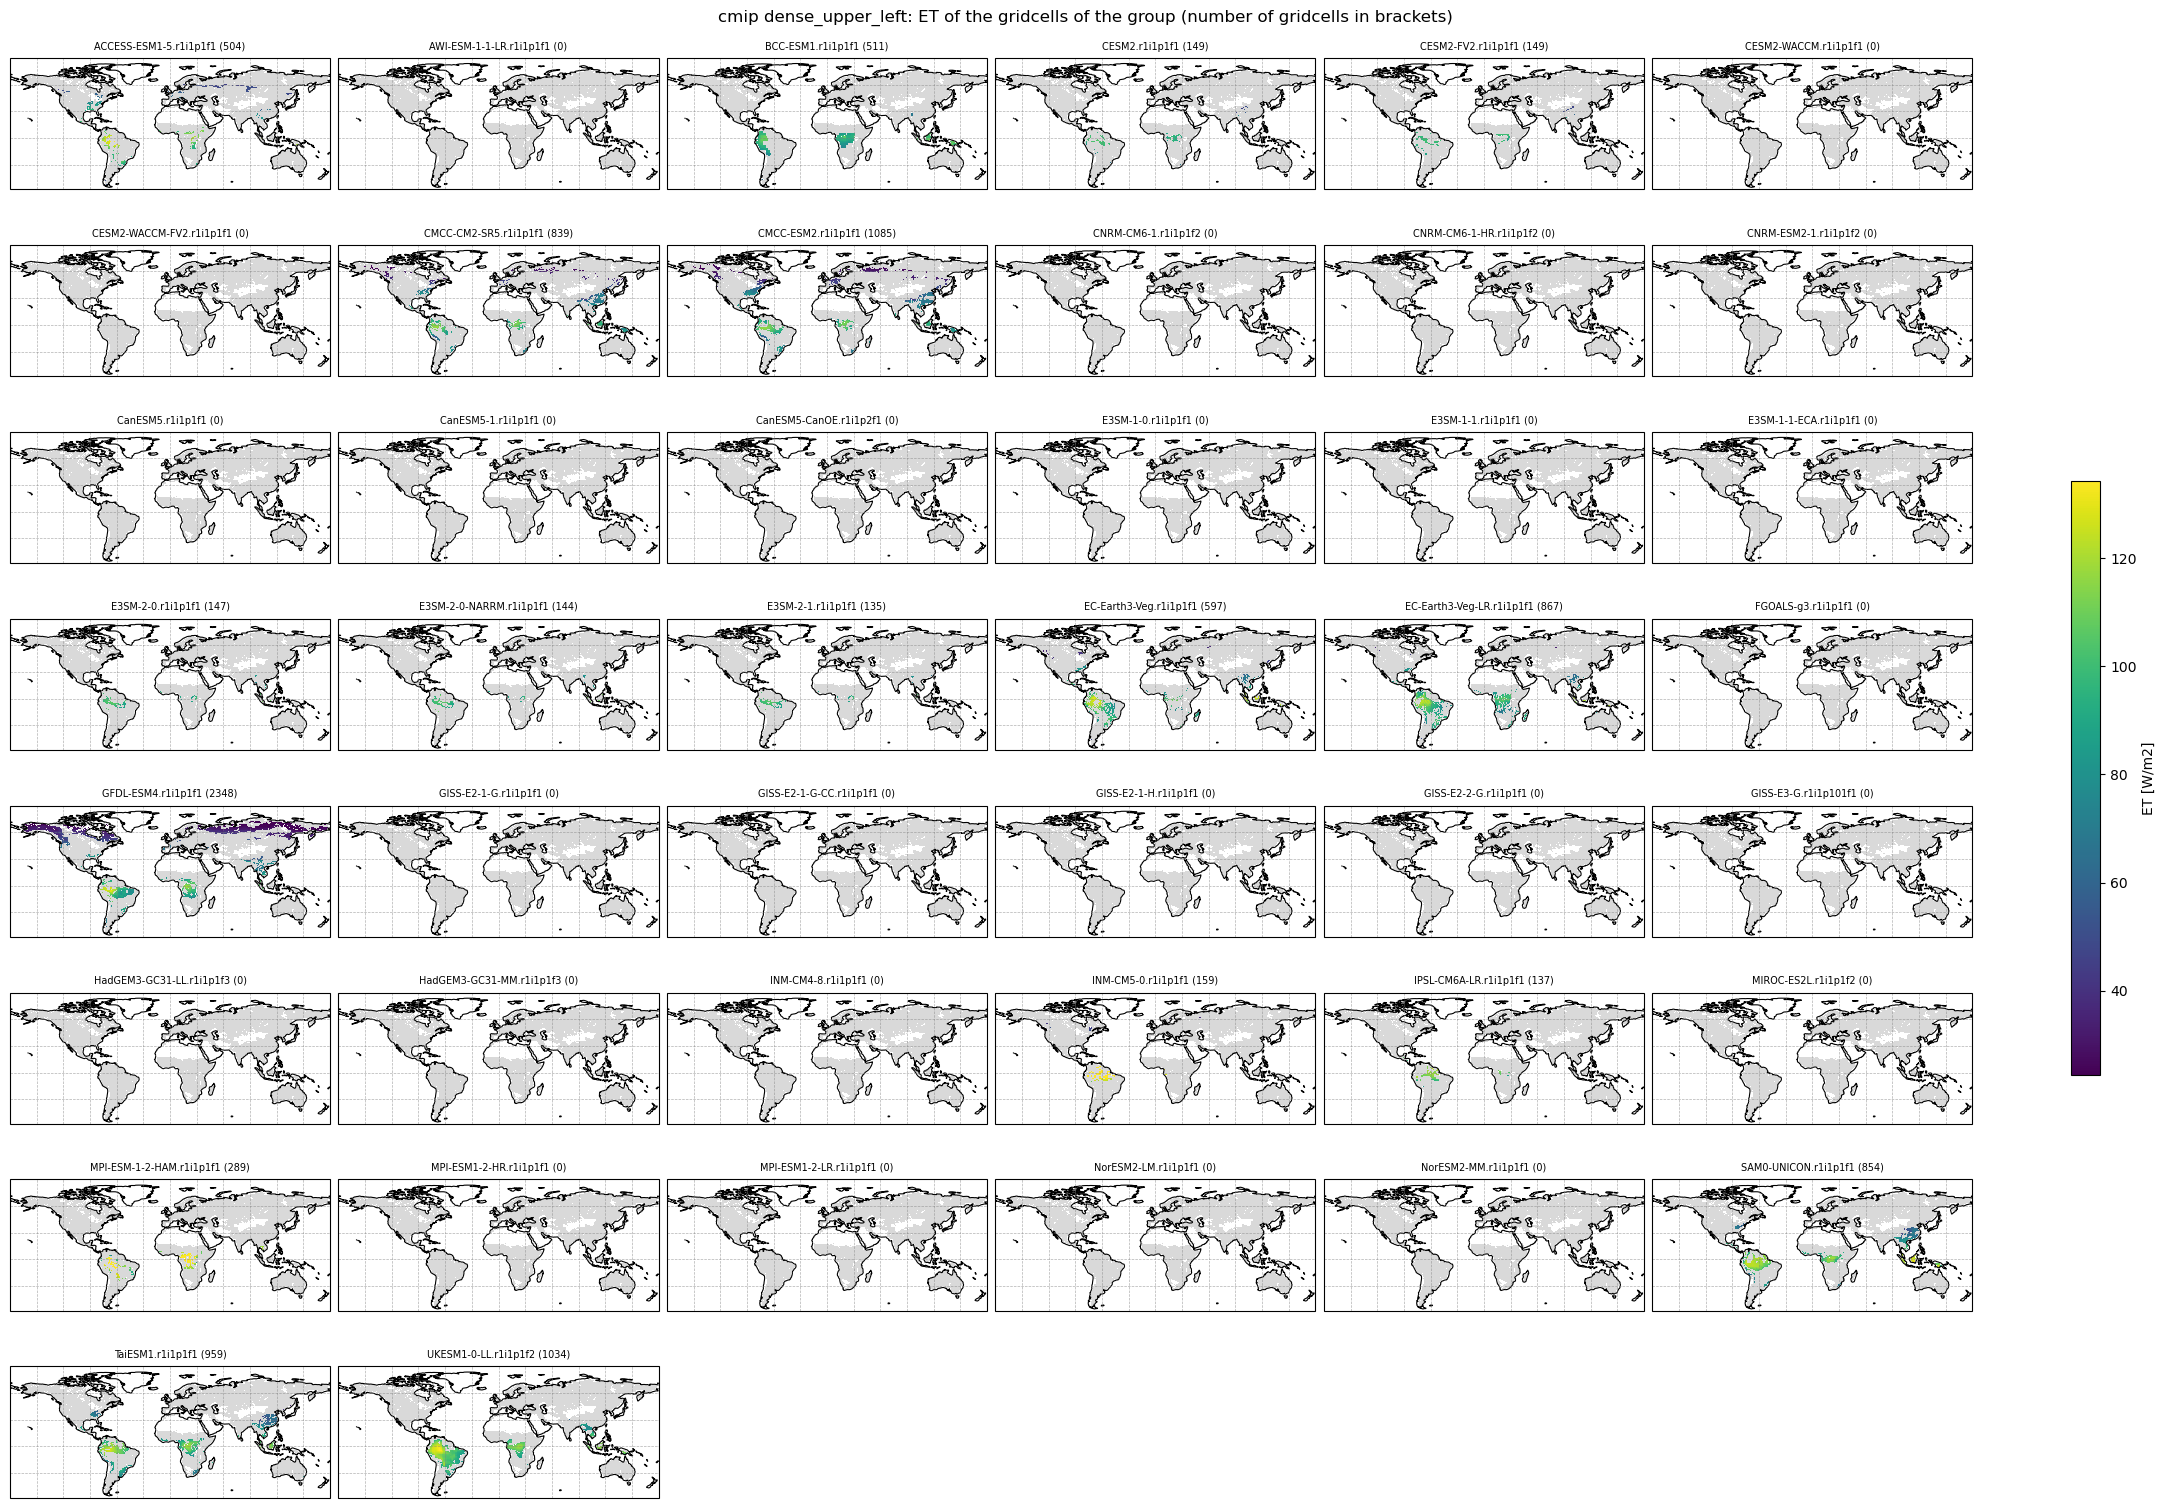

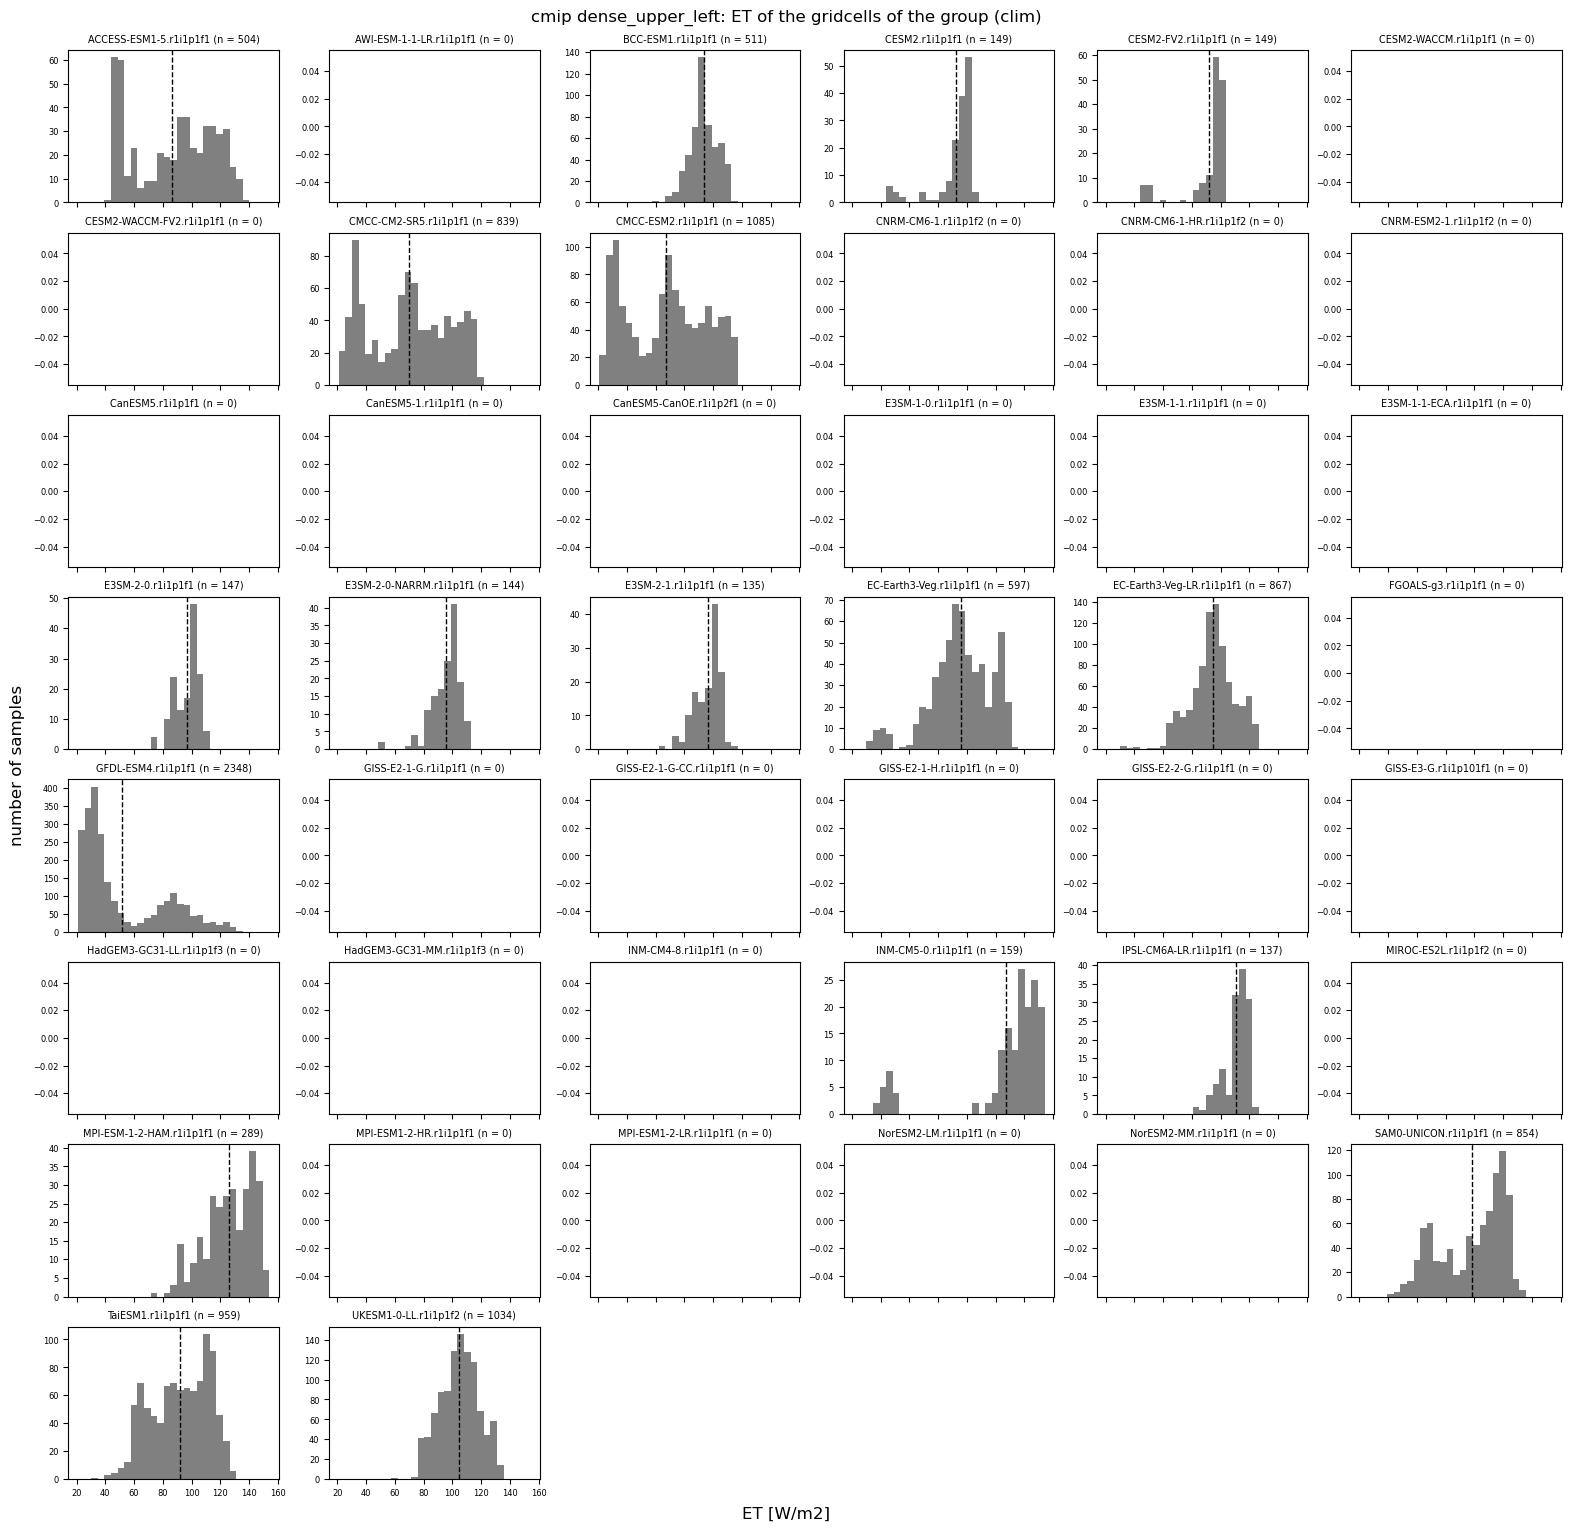

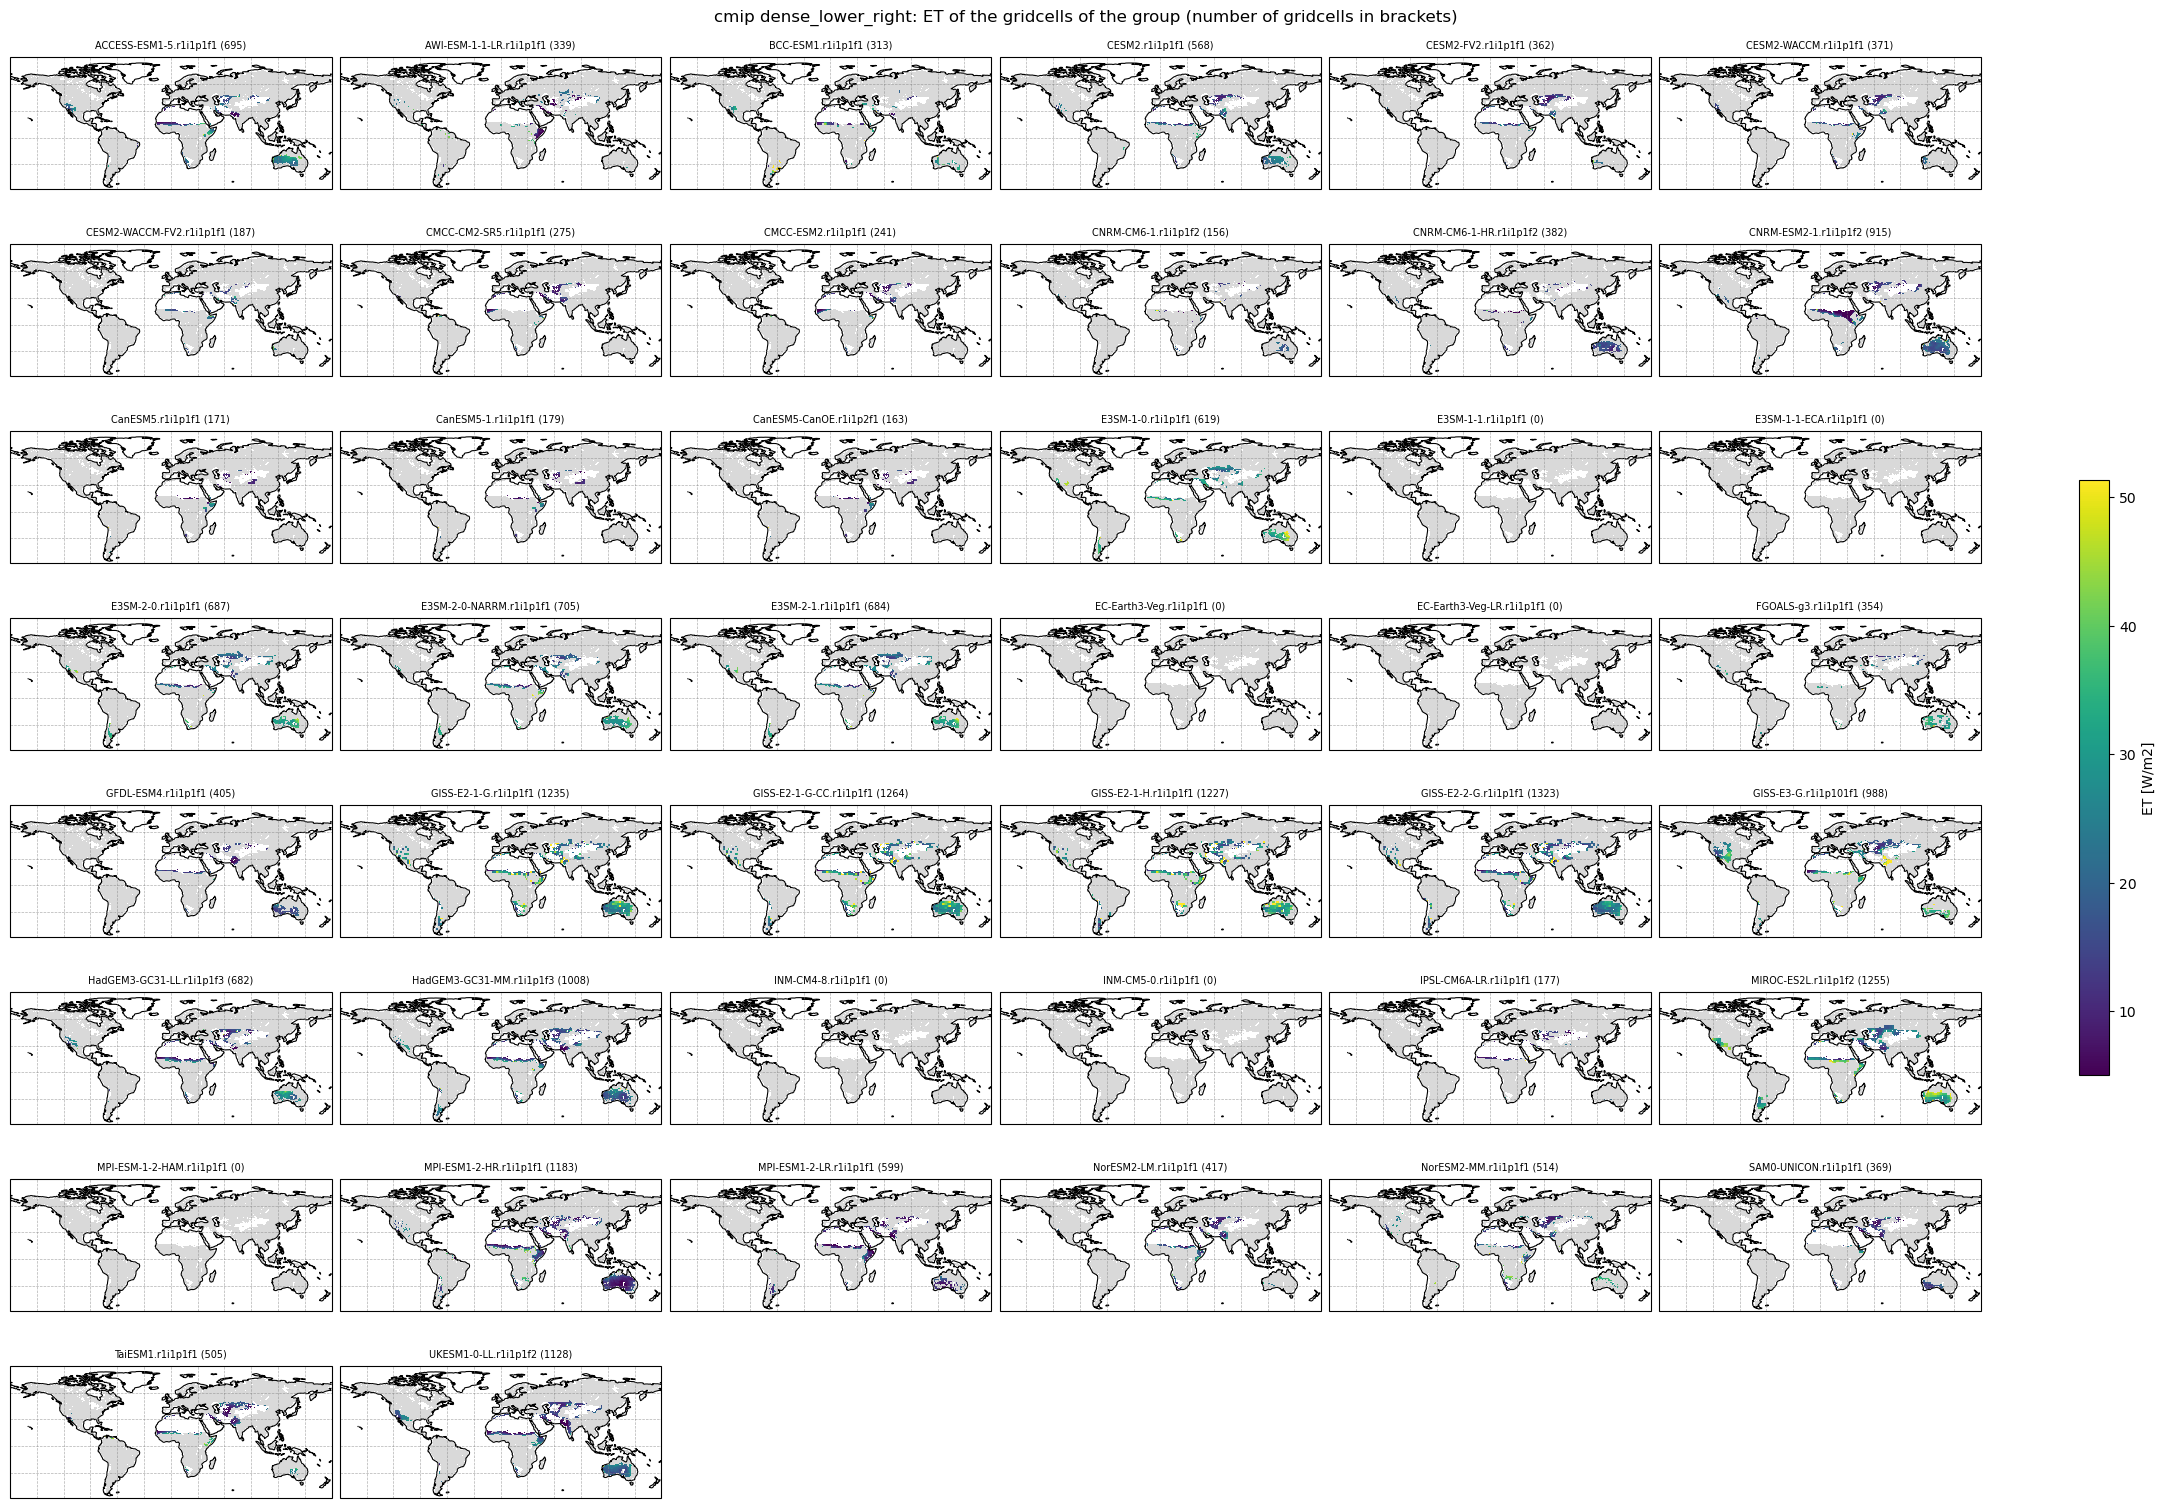

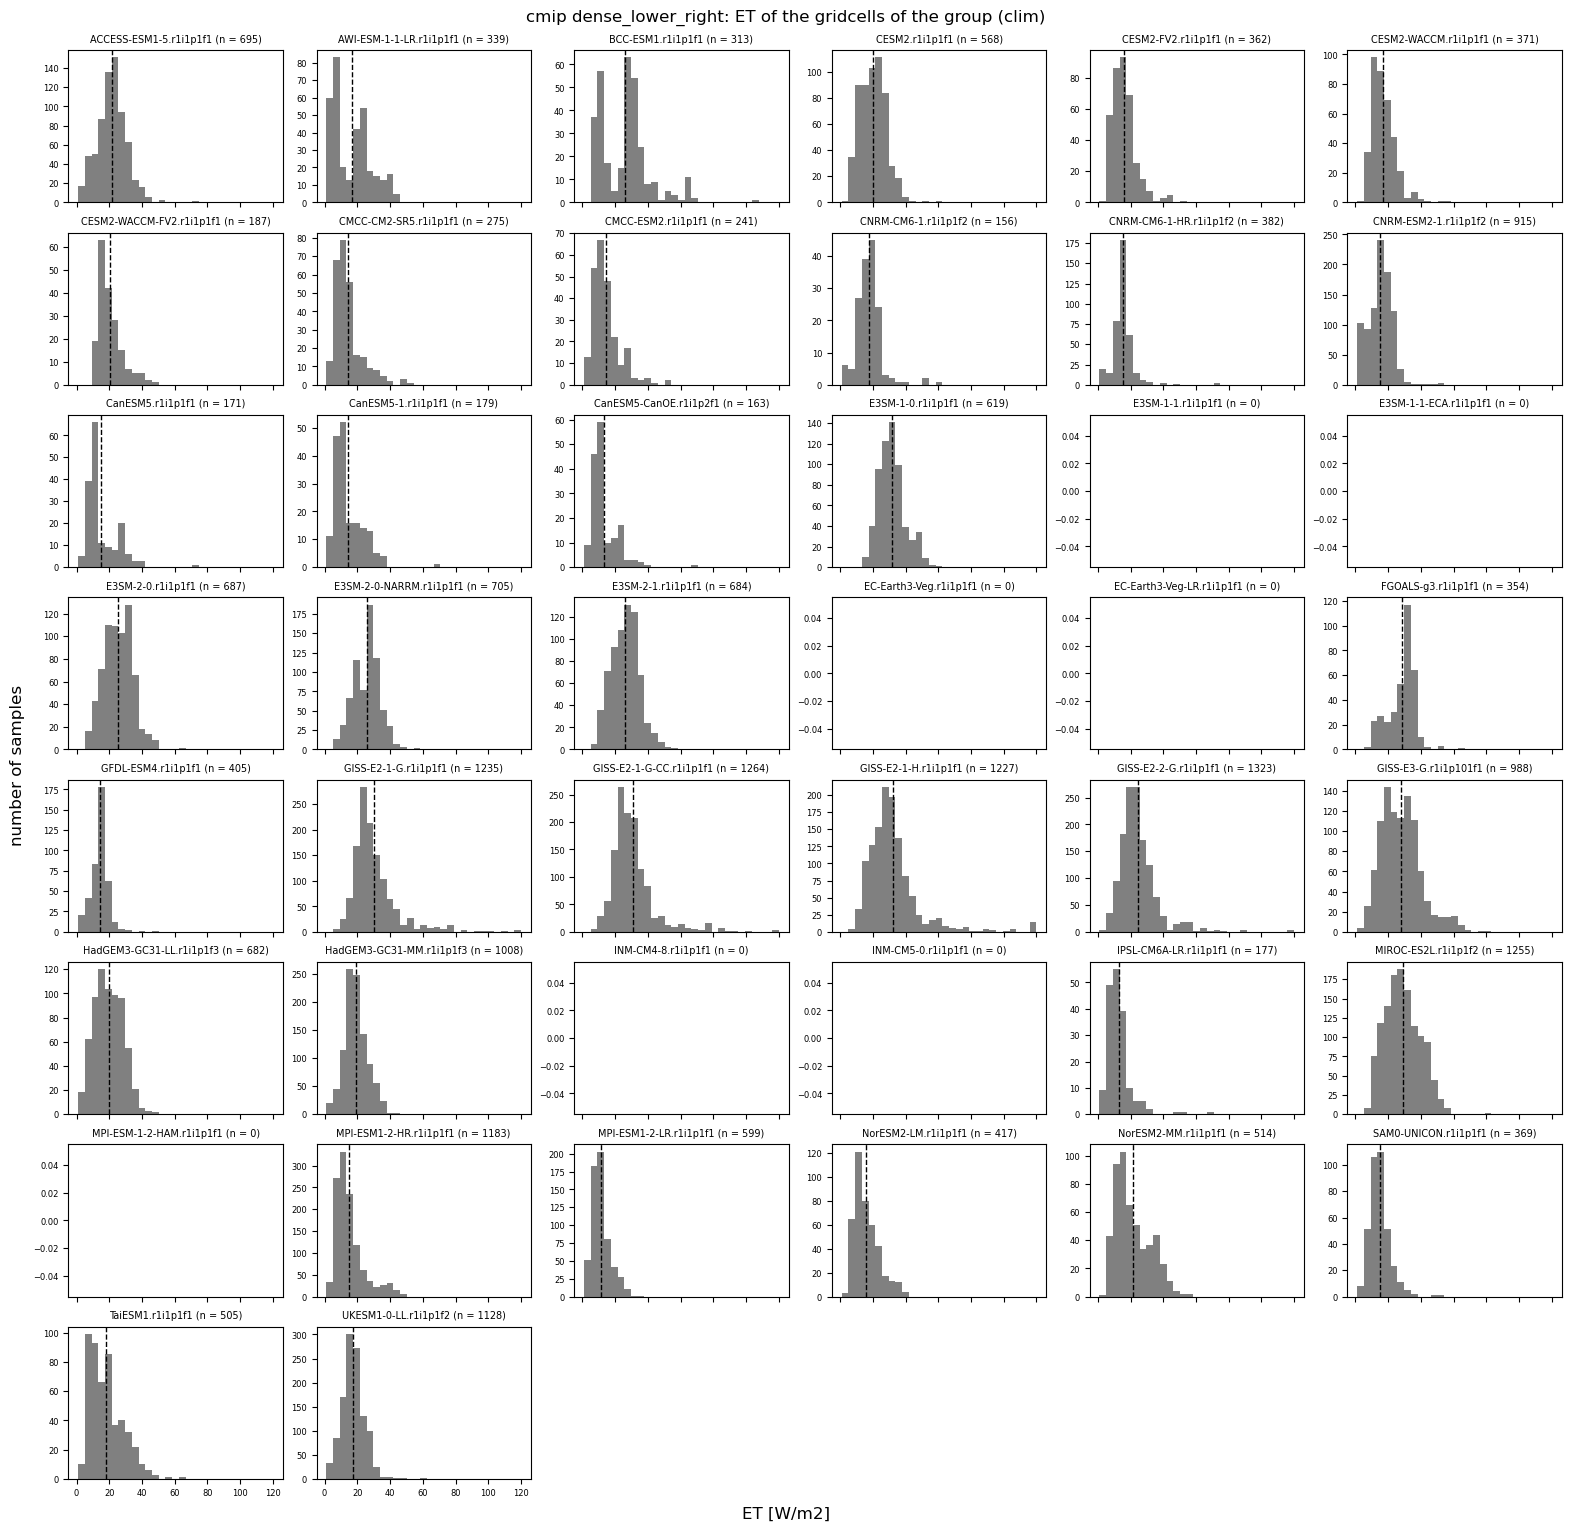

In [27]:
for group in DENSE_GROUPS:
    plot_member_maps(group)
    plot_member_hists(group)